# Concrete Compressive Strength Prediction - EDA, feature engineering, and baseline modeling

In [1]:
from pathlib import Path

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_SEED = 13

## 1 - Data preparation and preprocessing

- The original data files are in XLSX (MS Excel spreadsheet file).
- Since the number of observations are relatively low, initial fix of formatting was practically done in Excel.
- For each source, the formatted data was exported in CSV.

**Data Sources**

1. Source 1: [Concrete Compressive Strength Dataset](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength) (1030 observations)
2. Source 2: [High Performance Concrete Data](https://doi.org/10.6084/m9.figshare.25139018) (597 observations)

**References**

1. Source 1: [Modeling of strength of high performance concrete using artificial neural networks](https://doi.org/10.1016/S0008-8846(98)00165-3)
2. Source 2: [A novel artificial intelligence-aided system to mine historical high-performance concrete data for optimizing mixture design](https://doi.org/10.1016/j.eswa.2022.118605)

In [2]:
DATA_PATH = Path().resolve() / "data"
datasets = list(DATA_PATH.glob("data_src*.csv", case_sensitive=True))
datasets

[PosixPath('/mnt/d/Users/Esperine/Workspace3/_projects/_dev/buhos/data/data_src1.csv'),
 PosixPath('/mnt/d/Users/Esperine/Workspace3/_projects/_dev/buhos/data/data_src2.csv')]

In [3]:
df_src1 = pd.read_csv(datasets[0], skiprows=[1])
df_src1.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [4]:
df_src2 = pd.read_csv(datasets[1], skiprows=[1])
df_src2.head()

,cement,blast_furnace_slag,fly_ash,silica_fume,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength
0,440.0,0.0,0.0,0.0,167.0,8.8,1230.0,677.0,28,49.0
1,440.0,0.0,0.0,0.0,167.0,8.8,1230.0,677.0,90,55.0
2,440.0,0.0,0.0,0.0,167.0,8.8,1230.0,677.0,180,56.0
3,440.0,0.0,0.0,0.0,167.0,8.8,1230.0,677.0,365,60.0
4,308.0,0.0,132.0,0.0,167.0,8.8,1232.0,621.0,28,48.0


In [5]:
df_src1.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   cement                1030 non-null   float64
 1   blast_furnace_slag    1030 non-null   float64
 2   fly_ash               1030 non-null   float64
 3   water                 1030 non-null   float64
 4   superplasticizer      1030 non-null   float64
 5   coarse_aggregate      1030 non-null   float64
 6   fine_aggregate        1030 non-null   float64
 7   age                   1030 non-null   int64  
 8   compressive_strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [6]:
df_src2.info()

<class 'pandas.DataFrame'>
RangeIndex: 597 entries, 0 to 596
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   cement                597 non-null    float64
 1   blast_furnace_slag    597 non-null    float64
 2   fly_ash               597 non-null    float64
 3   silica_fume           597 non-null    float64
 4   water                 597 non-null    float64
 5   superplasticizer      597 non-null    float64
 6   coarse_aggregate      597 non-null    float64
 7   fine_aggregate        597 non-null    float64
 8   age                   597 non-null    int64  
 9   compressive_strength  597 non-null    float64
dtypes: float64(9), int64(1)
memory usage: 46.8 KB


In [7]:
# Add sample ID and source
df_src1["sample_id"] = "s1_" + (df_src1.index + 1).astype(str)
df_src1["src"] = "src1"
df_src1.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength,sample_id,src
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99,s1_1,src1
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89,s1_2,src1
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27,s1_3,src1
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05,s1_4,src1
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30,s1_5,src1


In [8]:
# Add sample ID and source
df_src2["sample_id"] = "s2_" + (df_src2.index + 1).astype(str)
df_src2["src"] = "src2"
df_src2.head()

,cement,blast_furnace_slag,fly_ash,silica_fume,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength,sample_id,src
0,440.0,0.0,0.0,0.0,167.0,8.8,1230.0,677.0,28,49.0,s2_1,src2
1,440.0,0.0,0.0,0.0,167.0,8.8,1230.0,677.0,90,55.0,s2_2,src2
2,440.0,0.0,0.0,0.0,167.0,8.8,1230.0,677.0,180,56.0,s2_3,src2
3,440.0,0.0,0.0,0.0,167.0,8.8,1230.0,677.0,365,60.0,s2_4,src2
4,308.0,0.0,132.0,0.0,167.0,8.8,1232.0,621.0,28,48.0,s2_5,src2


In [9]:
df_src1.shape, df_src2.shape

((1030, 11), (597, 12))

In [10]:
# Combine both set into a single dataframe
df = pd.concat([df_src1, df_src2], ignore_index=True)

# Only silica fume is missing in source 1 data, fill null with zero
df["silica_fume"] = df["silica_fume"].fillna(0)

df

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength,sample_id,src,silica_fume
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99,s1_1,src1,0.0
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89,s1_2,src1,0.0
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27,s1_3,src1,0.0
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05,s1_4,src1,0.0
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30,s1_5,src1,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1622,422.0,0.0,141.0,176.0,0.0,900.0,524.0,3,36.00,s2_593,src2,141.0
1623,422.0,0.0,141.0,176.0,0.0,900.0,524.0,7,54.00,s2_594,src2,141.0
1624,422.0,0.0,141.0,176.0,0.0,900.0,524.0,28,67.50,s2_595,src2,141.0
1625,422.0,0.0,141.0,176.0,0.0,900.0,524.0,56,72.00,s2_596,src2,141.0


In [11]:
# Reorganize original variables/features

columns = [
    "sample_id", 
    "src", 
    "cement", 
    "blast_furnace_slag", 
    "fly_ash", 
    "silica_fume", 
    "coarse_aggregate", 
    "fine_aggregate", 
    "water", 
    "superplasticizer", 
    "age", 
    "compressive_strength"
]

df = df.reindex(columns=columns)
df

,sample_id,src,cement,blast_furnace_slag,fly_ash,silica_fume,coarse_aggregate,fine_aggregate,water,superplasticizer,age,compressive_strength
0,s1_1,src1,540.0,0.0,0.0,0.0,1040.0,676.0,162.0,2.5,28,79.99
1,s1_2,src1,540.0,0.0,0.0,0.0,1055.0,676.0,162.0,2.5,28,61.89
2,s1_3,src1,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,270,40.27
3,s1_4,src1,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,365,41.05
4,s1_5,src1,198.6,132.4,0.0,0.0,978.4,825.5,192.0,0.0,360,44.30
...,...,...,...,...,...,...,...,...,...,...,...,...
1622,s2_593,src2,422.0,0.0,141.0,141.0,900.0,524.0,176.0,0.0,3,36.00
1623,s2_594,src2,422.0,0.0,141.0,141.0,900.0,524.0,176.0,0.0,7,54.00
1624,s2_595,src2,422.0,0.0,141.0,141.0,900.0,524.0,176.0,0.0,28,67.50
1625,s2_596,src2,422.0,0.0,141.0,141.0,900.0,524.0,176.0,0.0,56,72.00


In [12]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
cement,1627.0,286.455870,107.612973,102.00,194.700,280.00,359.5,611.00
blast_furnace_slag,1627.0,60.818285,78.673155,0.00,0.000,1.40,111.0,359.40
fly_ash,1627.0,72.428888,78.982539,0.00,0.000,68.00,132.0,350.00
silica_fume,1627.0,5.045446,17.810894,0.00,0.000,0.00,0.0,141.00
coarse_aggregate,1627.0,980.805532,102.311377,708.00,913.200,968.00,1047.0,1270.00
fine_aggregate,1627.0,765.326675,99.171792,523.00,699.000,774.00,840.5,992.60
water,1627.0,175.829533,24.810194,121.80,159.000,179.00,192.0,247.00
superplasticizer,1627.0,6.600870,6.193479,0.00,0.000,6.00,10.4,32.20
age,1627.0,48.527351,66.770750,1.00,14.000,28.00,56.0,365.00
compressive_strength,1627.0,40.060535,19.509901,2.33,25.655,37.72,52.0,113.15


In [13]:
df["compressive_strength"].quantile((0.1, 0.9))

0.1    15.598
0.9    67.500
Name: compressive_strength, dtype: float64

In [14]:
df["compressive_strength"].quantile((0.01, 0.99))

0.01     7.4286
0.99    95.0000
Name: compressive_strength, dtype: float64

In [15]:
# Export merged data for later use
file_path = DATA_PATH / "concrete_data_full.csv"
df.to_csv(file_path, index=False)

file_path.is_file()

True

## 2 - Exploratory analysis

### 2.1 - Distribution of compressive strength

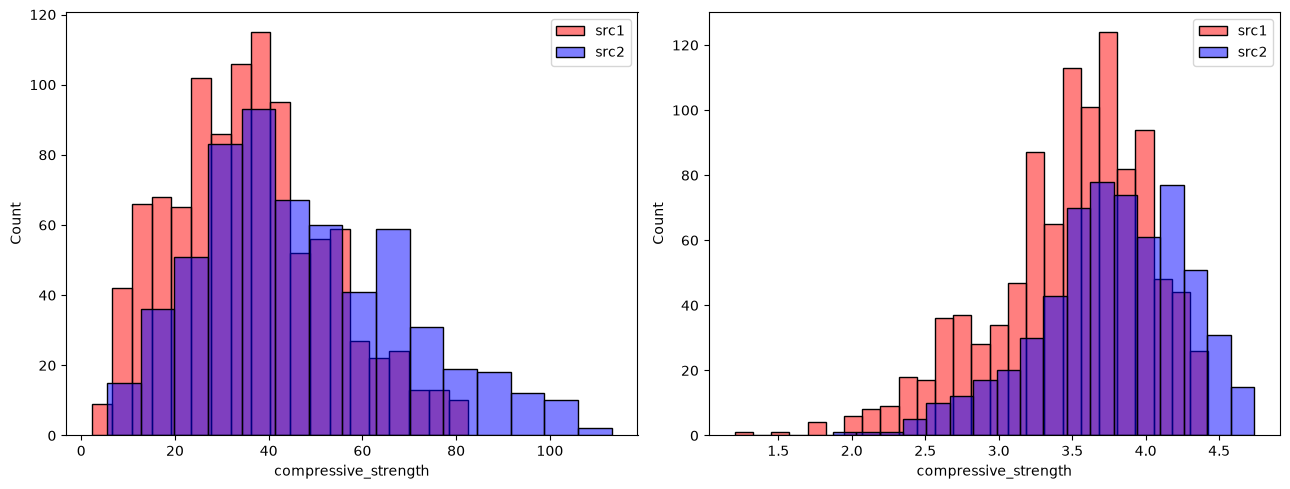

In [16]:
filter_src1 = (df["src"] == "src1")
filter_src2 = (df["src"] == "src2")

src1_samples = df[filter_src1]["compressive_strength"]
src2_samples = df[filter_src2]["compressive_strength"]

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

sns.histplot(src1_samples, color="red", alpha=0.5, ax=ax1, label="src1")
sns.histplot(src2_samples, color="blue", alpha=0.5, ax=ax1, label="src2")
ax1.legend()

# Checking based on log values
sns.histplot(np.log1p(src1_samples), color="red", alpha=0.5, ax=ax2, label="src1")
sns.histplot(np.log1p(src2_samples), color="blue", alpha=0.5, ax=ax2, label="src2")
ax2.legend()

fig.tight_layout()

- Distribution is slightly mismatched given source 2 (blue) has wider variance and longer right tail
- Compressive strengths above 80 are populated almost exclusively by source 2, the model will associate high strength solely with the specific feature signatures of source 2
- Uneven spread between distributions -> usual linear models are not suitable for making prediction

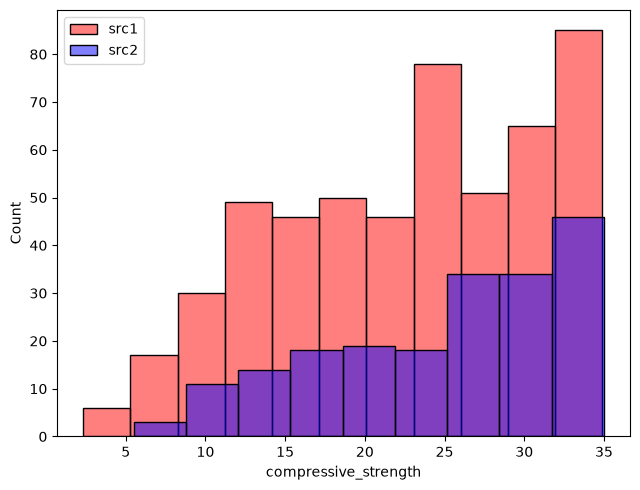

In [17]:
# Consider only typical strength used in general construction (<=35 MPa)

filter_src1 = (df["src"] == "src1")
filter_src2 = (df["src"] == "src2")
filter_typ_str = (df["compressive_strength"] <= 35)

src1_samples = df[filter_src1 & filter_typ_str]["compressive_strength"]
src2_samples = df[filter_src2 & filter_typ_str]["compressive_strength"]

fig, ax = plt.subplots(figsize=(6.5, 5))

sns.histplot(src1_samples, color="red", alpha=0.5, ax=ax, label="src1")
sns.histplot(src2_samples, color="blue", alpha=0.5, ax=ax, label="src2")
ax.legend()

fig.tight_layout()

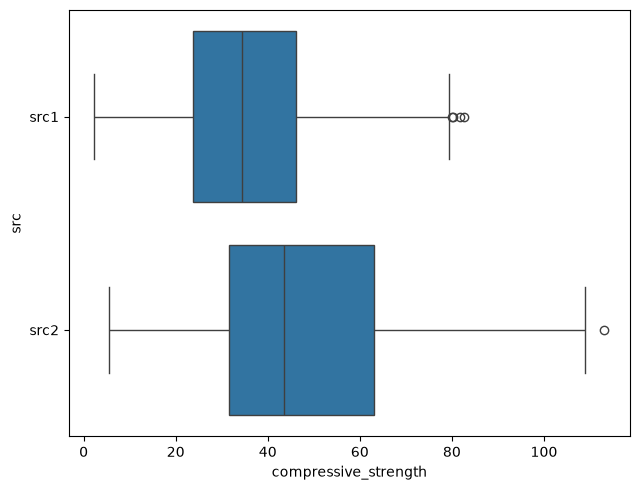

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 5))

sns.boxplot(df, x="compressive_strength", y="src", orient="h", ax=ax)

fig.tight_layout()

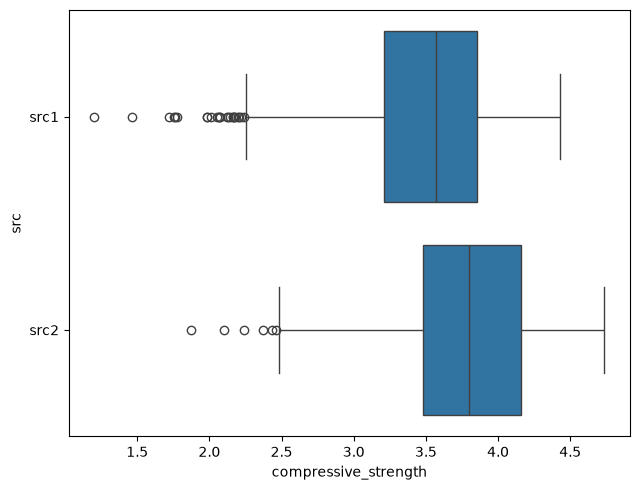

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 5))

sns.boxplot(df, x=np.log1p(df["compressive_strength"]), y="src", orient="h", ax=ax)

fig.tight_layout()

In [20]:
np.log1p(df["compressive_strength"]).quantile((0.1, 0.9))

0.1    2.809282
0.9    4.226834
Name: compressive_strength, dtype: float64

In [21]:
np.expm1(2.80928), np.expm1(4.226834)

(np.float64(15.597963381926895), np.float64(67.50001744913193))

### 2.2 - Relationship between variables

- Derive key variables for exploratory analysis.
- In concrete mix design, we are most interested in any relationship involving the following materials:
    1. Cement
    2. Supplementary cementitious materials (SCM) (i.e. Blast surface slag, Fly ash, Silica fume, etc.)
    3. Water
- Regarding age of concrete, note that strength gains rapidly early on and asymptotes over time. Hence scaling the age value might yield benefits during training.

In [22]:
# Duplicate dataframe
df_eda = df.copy()

# Scale age into logarithmic
df_eda["log_age"] = np.log1p(df_eda["age"])

# Variables related to binding material - cement and SCMs
scm_mats = ["blast_furnace_slag", "fly_ash", "silica_fume"]
df_eda["total_scm"] = df_eda[scm_mats].sum(axis=1)
df_eda["total_binder"] = df_eda["cement"] + df_eda["total_scm"]

# Water-cement ratio
df_eda["ratio_wc"] = df_eda["water"].div(df_eda["cement"]).replace([np.inf, -np.inf, np.nan], 0)

# Water binder ratio
df_eda["ratio_wb"] = df_eda["water"].div(df_eda["total_binder"]).replace([np.inf, -np.inf, np.nan], 0)

# Percent of binder replaced by SCMs
df_eda["pct_scm_repl"] = df_eda["total_scm"].div(df_eda["total_binder"]).replace([np.inf, -np.inf, np.nan], 0)

In [23]:
df_eda.head()

,sample_id,src,cement,blast_furnace_slag,fly_ash,silica_fume,coarse_aggregate,fine_aggregate,water,superplasticizer,age,compressive_strength,log_age,total_scm,total_binder,ratio_wc,ratio_wb,pct_scm_repl
0,s1_1,src1,540.0,0.0,0.0,0.0,1040.0,676.0,162.0,2.5,28,79.99,3.367296,0.0,540.0,0.300000,0.30000,0.0
1,s1_2,src1,540.0,0.0,0.0,0.0,1055.0,676.0,162.0,2.5,28,61.89,3.367296,0.0,540.0,0.300000,0.30000,0.0
2,s1_3,src1,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,270,40.27,5.602119,142.5,475.0,0.685714,0.48000,0.3
3,s1_4,src1,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,365,41.05,5.902633,142.5,475.0,0.685714,0.48000,0.3
4,s1_5,src1,198.6,132.4,0.0,0.0,978.4,825.5,192.0,0.0,360,44.30,5.888878,132.4,331.0,0.966767,0.58006,0.4


Set bins for age of concrete

- 0-7 days
- 7-14 days
- 14-28 days
- 28+ days

In [24]:
df_eda["age"].max()

np.int64(365)

In [25]:
age_bin_edges = [0, 7, 14, 28, 365]
age_bin_labels = ["0-7", "7-14", "14-28", ">28"]

df_eda["age_range"] = pd.cut(df_eda["age"], bins=age_bin_edges, labels=age_bin_labels, include_lowest=True)
df_eda.head()

,sample_id,src,cement,blast_furnace_slag,fly_ash,silica_fume,coarse_aggregate,fine_aggregate,water,superplasticizer,age,compressive_strength,log_age,total_scm,total_binder,ratio_wc,ratio_wb,pct_scm_repl,age_range
0,s1_1,src1,540.0,0.0,0.0,0.0,1040.0,676.0,162.0,2.5,28,79.99,3.367296,0.0,540.0,0.300000,0.30000,0.0,14-28
1,s1_2,src1,540.0,0.0,0.0,0.0,1055.0,676.0,162.0,2.5,28,61.89,3.367296,0.0,540.0,0.300000,0.30000,0.0,14-28
2,s1_3,src1,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,270,40.27,5.602119,142.5,475.0,0.685714,0.48000,0.3,>28
3,s1_4,src1,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,365,41.05,5.902633,142.5,475.0,0.685714,0.48000,0.3,>28
4,s1_5,src1,198.6,132.4,0.0,0.0,978.4,825.5,192.0,0.0,360,44.30,5.888878,132.4,331.0,0.966767,0.58006,0.4,>28


In [26]:
df_eda["age_range"].value_counts().sort_index().reset_index()

,age_range,count
0,0-7,406
1,7-14,62
2,14-28,690
3,>28,469


Filter notes

- Typical strength in most construction use is less than 35 MPa, anything above is usually considered as high strength concrete.
- Assume full curing at 28 days of age, where the concrete has completely developed its target strength.
- Adding superplasticizers in a mix improves its workability and flow without adding water.
- SCMs serve as partial replacement to cement in a concrete mix.

In [27]:
# Setup relevant filters

filter_typ_str = (df_eda["compressive_strength"] <= 35)
filter_no_scm = (df_eda["pct_scm_repl"] == 0)
filter_no_superplasticizer = (df_eda["superplasticizer"] == 0)
filter_fully_cured = (df_eda["age"] >= 28)
filter_not_fully_cured = (df_eda["age"] < 28)

Set conditions for "normal" concrete mix for later use

- Less than or equal to 35 MPa at 28 days or more
- No superplasticizer added (water reducer admixture that increase fluidity and workability while reducing water)
- No supplementary cementitious material (SCM) added

In [28]:
normal_mix_df = df_eda[filter_typ_str & filter_no_scm & filter_no_superplasticizer & filter_fully_cured]
print(normal_mix_df.shape)
normal_mix_df.head()

(73, 19)


,sample_id,src,cement,blast_furnace_slag,fly_ash,silica_fume,coarse_aggregate,fine_aggregate,water,superplasticizer,age,compressive_strength,log_age,total_scm,total_binder,ratio_wc,ratio_wb,pct_scm_repl,age_range
376,s1_377,src1,376.0,0.0,0.0,0.0,1003.5,762.4,214.6,0.0,28,31.97,3.367296,0.0,376.0,0.570745,0.570745,0.0,14-28
531,s1_532,src1,436.0,0.0,0.0,0.0,838.4,719.7,218.0,0.0,28,23.85,3.367296,0.0,436.0,0.500000,0.500000,0.0,14-28
532,s1_533,src1,289.0,0.0,0.0,0.0,913.2,895.3,192.0,0.0,90,32.07,4.510860,0.0,289.0,0.664360,0.664360,0.0,>28
542,s1_543,src1,255.0,0.0,0.0,0.0,889.8,945.0,192.0,0.0,90,21.86,4.510860,0.0,255.0,0.752941,0.752941,0.0,>28
545,s1_546,src1,255.0,0.0,0.0,0.0,889.8,945.0,192.0,0.0,28,18.75,3.367296,0.0,255.0,0.752941,0.752941,0.0,14-28


#### 2.2.1 - Age and strength

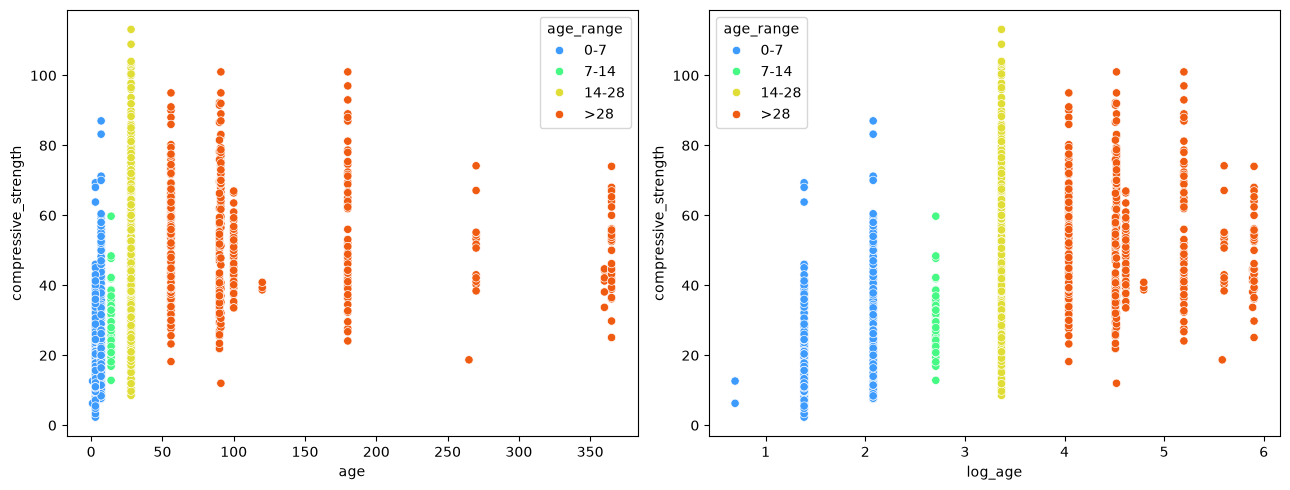

In [29]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

sns.scatterplot(data=df_eda, x="age", y="compressive_strength", hue="age_range", palette="turbo", ax=ax1)
sns.scatterplot(data=df_eda, x="log_age", y="compressive_strength", hue="age_range", palette="turbo", ax=ax2)

fig.tight_layout()

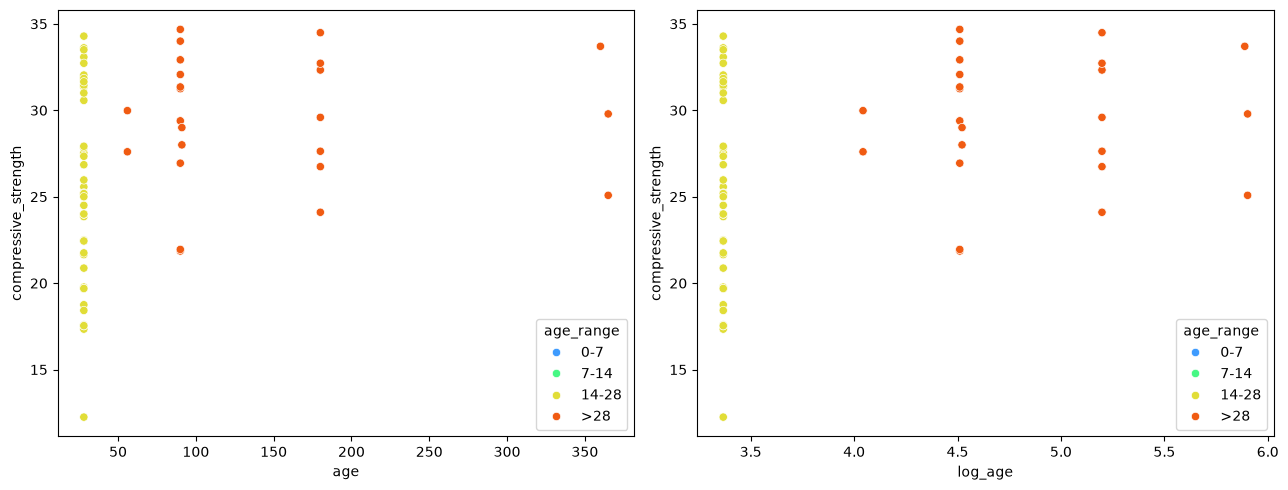

In [30]:
# Normal mix

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

sns.scatterplot(data=normal_mix_df, x="age", y="compressive_strength", hue="age_range", palette="turbo", ax=ax1)
sns.scatterplot(data=normal_mix_df, x="log_age", y="compressive_strength", hue="age_range", palette="turbo", ax=ax2)

fig.tight_layout()

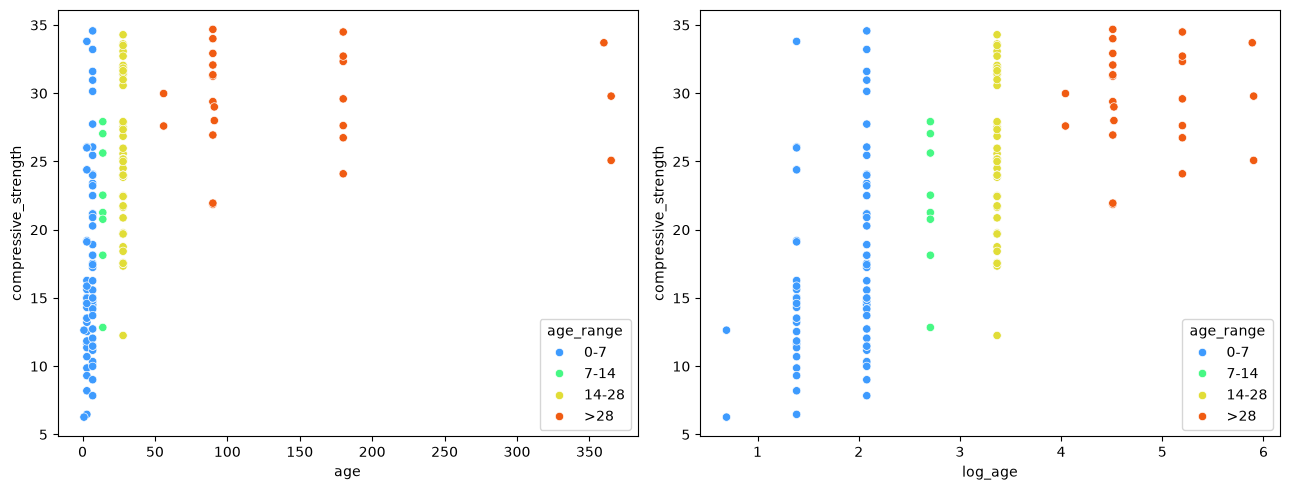

In [31]:
# Removing age limit

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

df_temp = df_eda[filter_typ_str & filter_no_scm & filter_no_superplasticizer]
sns.scatterplot(data=df_temp, x="age", y="compressive_strength", hue="age_range", palette="turbo", ax=ax1)
sns.scatterplot(data=df_temp, x="log_age", y="compressive_strength", hue="age_range", palette="turbo", ax=ax2)

fig.tight_layout()

#### 2.2.2 - Water-binder ratio and strength

- Verify expected inverse relationship between water-binder ratio (w/b or w/cm) and strength
- If no SCM added, the ratio can also be read as the water-cement ratio (w/c)

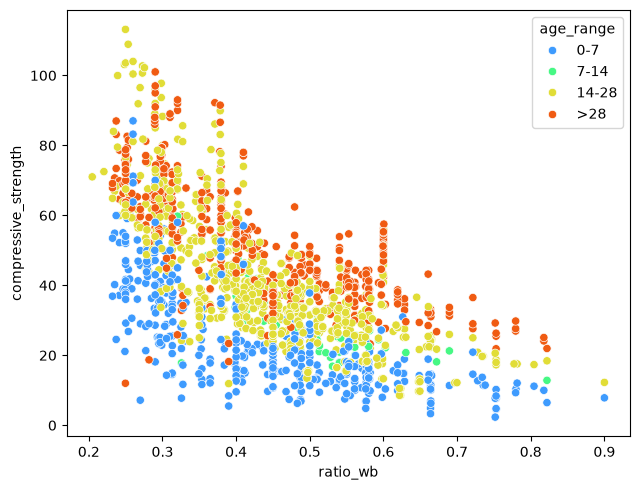

In [32]:
fig, ax = plt.subplots(figsize=(6.5, 5))

sns.scatterplot(data=df_eda, x="ratio_wb", y="compressive_strength", hue="age_range", palette="turbo", ax=ax)

fig.tight_layout()

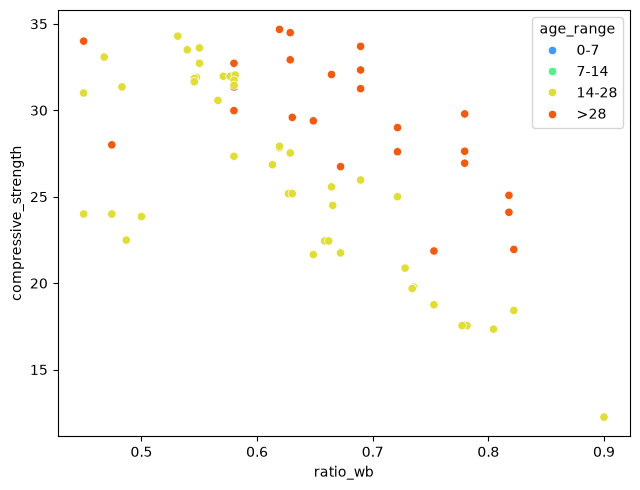

In [33]:
# Normal mix

fig, ax = plt.subplots(figsize=(6.5, 5))

sns.scatterplot(data=normal_mix_df, x="ratio_wb", y="compressive_strength", hue="age_range", palette="turbo", ax=ax)

fig.tight_layout()

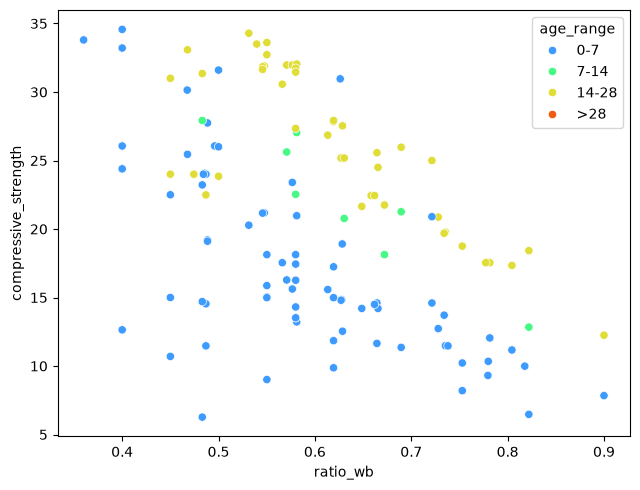

In [34]:
fig, ax = plt.subplots(figsize=(6.5, 5))

sns.scatterplot(
    data=df_eda[filter_typ_str & filter_no_scm & filter_no_superplasticizer & (df_eda["age"] <= 28)], 
    x="ratio_wb", 
    y="compressive_strength", 
    hue="age_range", 
    palette="turbo",
    ax=ax
)

fig.tight_layout()

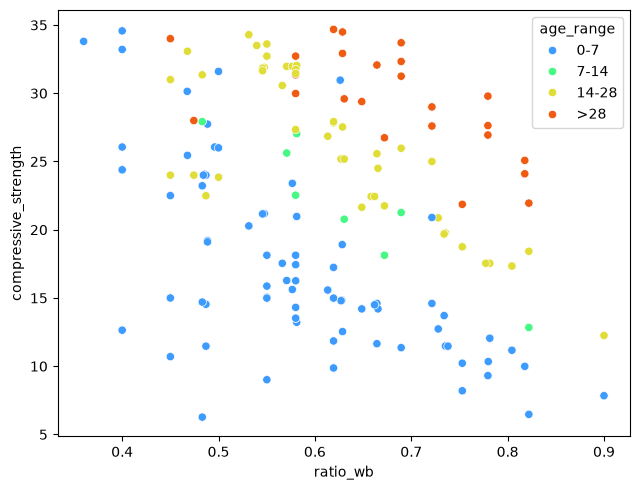

In [35]:
# Removing age

fig, ax = plt.subplots(figsize=(6.5, 5))

df_temp = df_eda[filter_typ_str & filter_no_scm & filter_no_superplasticizer]
sns.scatterplot(
    data=df_temp, 
    x="ratio_wb", 
    y="compressive_strength", 
    hue="age_range", 
    palette="turbo",
    ax=ax
)

fig.tight_layout()

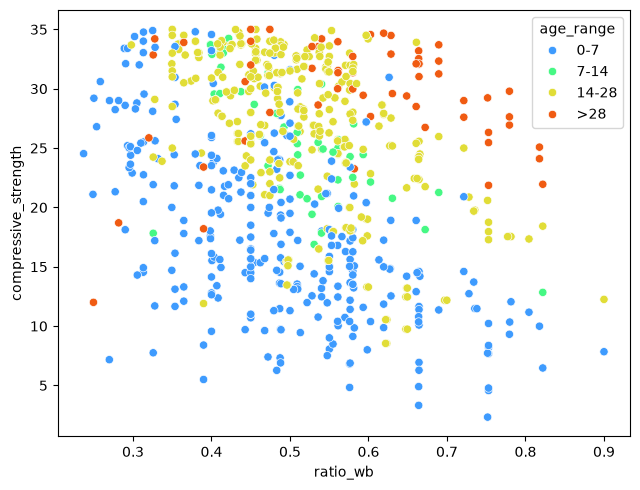

In [36]:
# Consider strength filter

fig, ax = plt.subplots(figsize=(6.5, 5))

sns.scatterplot(
    data=df_eda[filter_typ_str], 
    x="ratio_wb", 
    y="compressive_strength", 
    hue="age_range", 
    palette="turbo",
    ax=ax
)

fig.tight_layout()

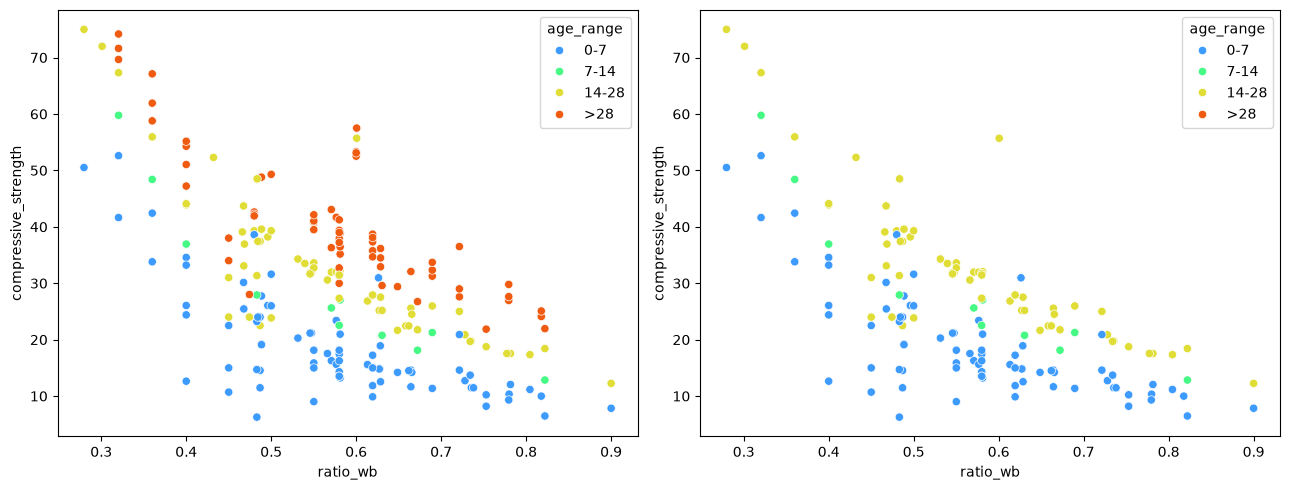

In [37]:
# Without SCM and superplasticizer included

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

sns.scatterplot(
    data=df_eda[filter_no_scm & filter_no_superplasticizer], 
    x="ratio_wb", 
    y="compressive_strength", 
    hue="age_range", 
    palette="turbo",
    ax=ax1
)
sns.scatterplot(
    data=df_eda[filter_no_scm & filter_no_superplasticizer & (df_eda["age"] <= 28)], 
    x="ratio_wb", 
    y="compressive_strength", 
    hue="age_range", 
    palette="turbo",
    ax=ax2
)

fig.tight_layout()

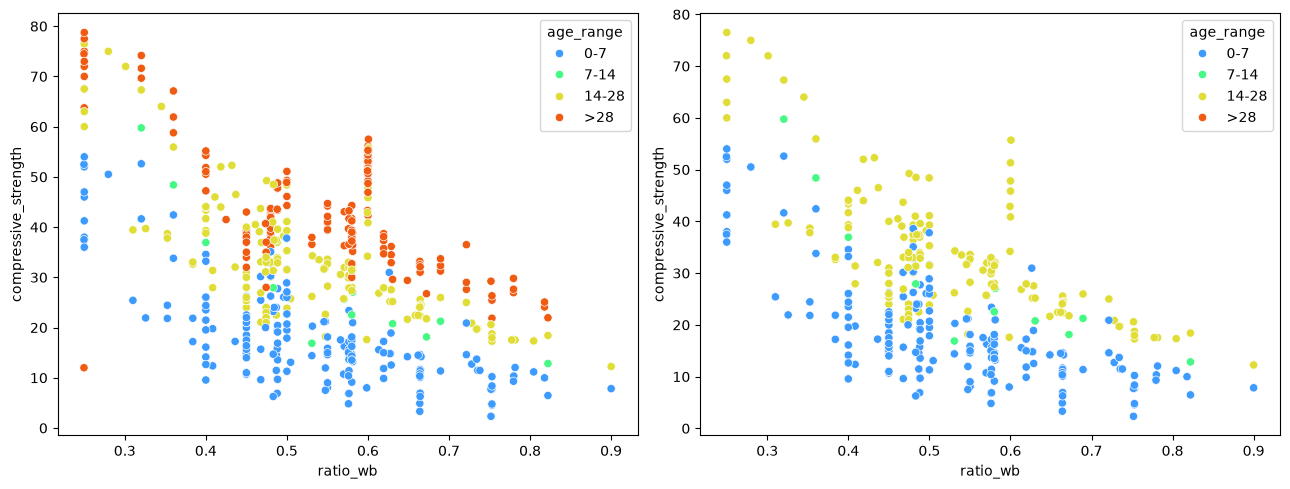

In [38]:
# Without SCM included

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

sns.scatterplot(
    data=df_eda[filter_no_superplasticizer], 
    x="ratio_wb", 
    y="compressive_strength", 
    hue="age_range", 
    palette="turbo",
    ax=ax1
)
sns.scatterplot(
    data=df_eda[filter_no_superplasticizer & (df_eda["age"] <= 28)], 
    x="ratio_wb", 
    y="compressive_strength", 
    hue="age_range", 
    palette="turbo",
    ax=ax2
)

fig.tight_layout()

Based on the plots we can generally observe that as the water-binder ratio increases (or the amount of water in the mix increases than the amount of cement and other binding materials) the strength of concrete decreases. Thus showing the concept of [Abrams' law](en.wikipedia.org/wiki/Abrams'_law).

#### 2.2.3 - SCM and strength

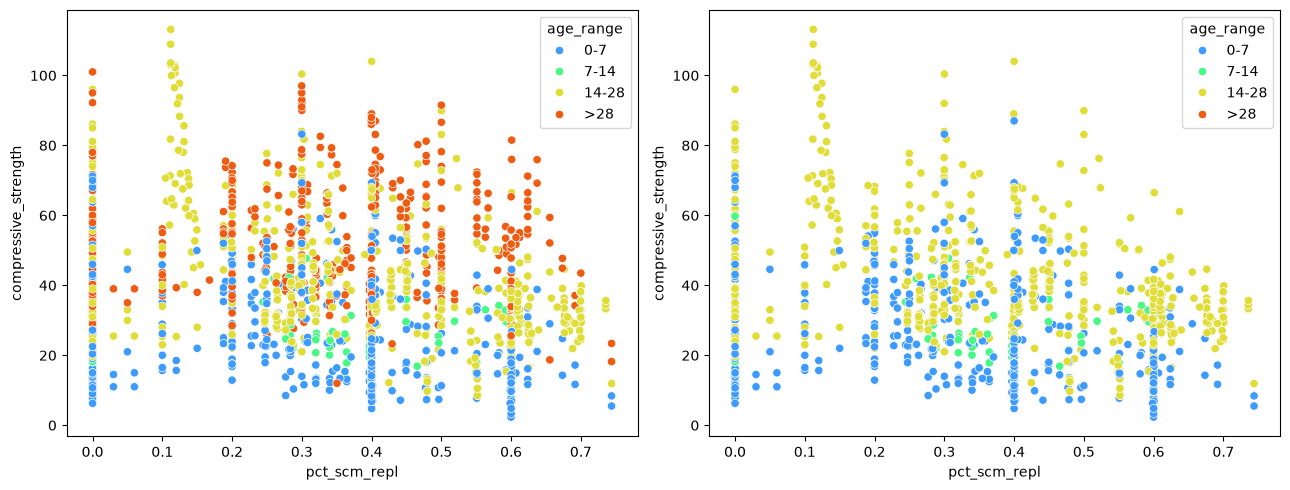

In [39]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

sns.scatterplot(
    data=df_eda, 
    x="pct_scm_repl", 
    y="compressive_strength", 
    hue="age_range", 
    palette="turbo", 
    ax=ax1
)
sns.scatterplot(
    data=df_eda[df_eda["age"] <= 28], 
    x="pct_scm_repl", 
    y="compressive_strength", 
    hue="age_range", 
    palette="turbo", 
    ax=ax2
)

fig.tight_layout()

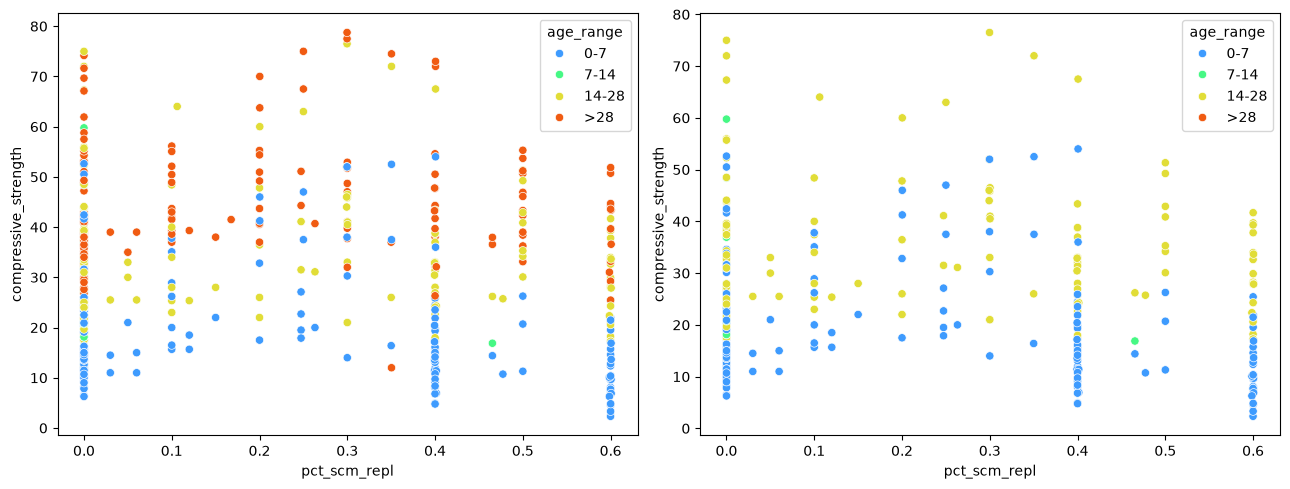

In [40]:
# Without plasticizer included

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

sns.scatterplot(
    data=df_eda[filter_no_superplasticizer], 
    x="pct_scm_repl", 
    y="compressive_strength", 
    hue="age_range", 
    palette="turbo",
    ax=ax1
)

sns.scatterplot(
    data=df_eda[filter_no_superplasticizer & (df_eda["age"] <= 28)], 
    x="pct_scm_repl", 
    y="compressive_strength", 
    hue="age_range", 
    palette="turbo",
    ax=ax2
)

fig.tight_layout()

#### 2.2.4 - Correlation heatmap

In [41]:
columns = [
    "sample_id", 
    "src", 
    "cement", 
    "blast_furnace_slag", 
    "fly_ash", 
    "silica_fume", 
    "coarse_aggregate", 
    "fine_aggregate", 
    "water", 
    "superplasticizer", 
    "age", 
    "log_age",
    "total_scm",
    "ratio_wc",
    "ratio_wb",
    "pct_scm_repl"
]

corr_mat = df_eda[columns].corr(numeric_only=True)

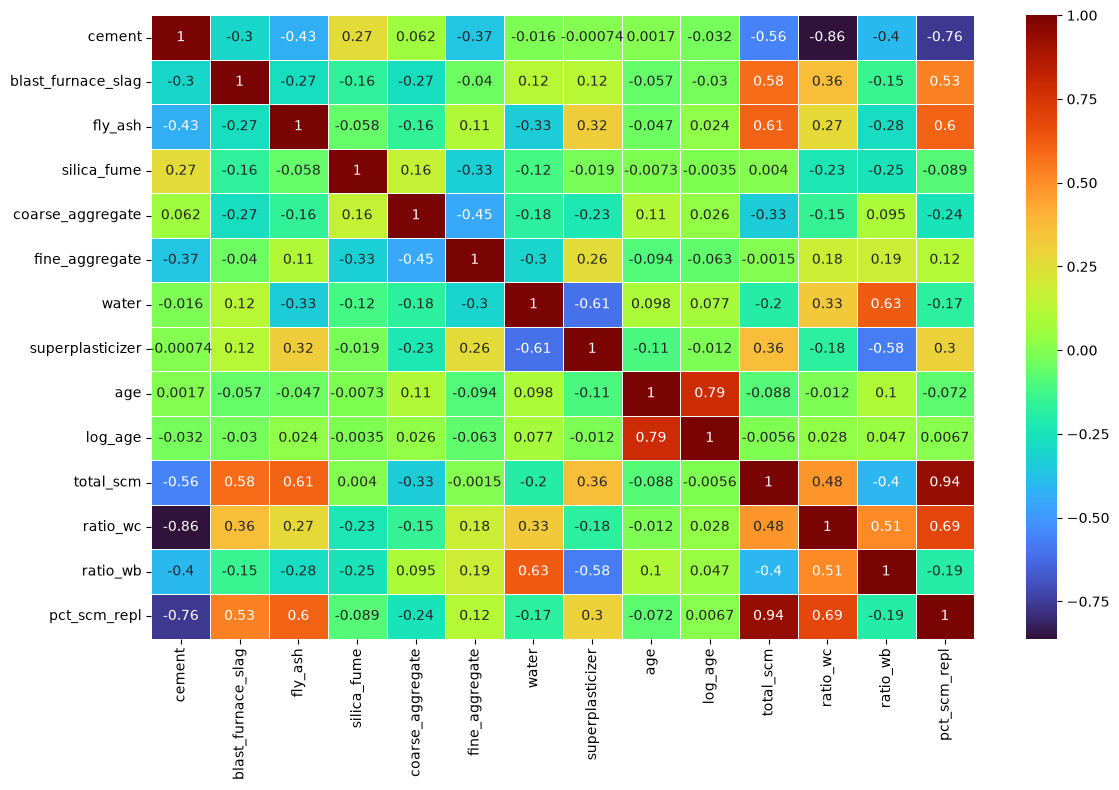

In [42]:
fig, ax = plt.subplots(figsize=(12, 8))

sns.heatmap(
    corr_mat,
    linewidths=0.5,
    cmap="turbo", 
    annot=True, 
    ax=ax
)

fig.tight_layout()

In [43]:
corr_upper_tri = corr_mat.where(np.triu(np.ones(corr_mat.shape), k=1).astype(bool))
threshold = 0.7
high_corr = corr_upper_tri.unstack().dropna()
high_corr_pairs = high_corr[high_corr.abs() > threshold]

high_corr_pairs

log_age       age          0.785737
ratio_wc      cement      -0.860914
pct_scm_repl  cement      -0.759299
              total_scm    0.937237
dtype: float64

Relevant pairs with strong correlation (>0.7)

- `cement` and `pct_scm_repl`
- `cement` and `ratio_wc`
- `age` and `log_age` (irrelevant since one of them needs to be dropped before training)

## 3 - Baseline modeling and feature importance

- From referenced literature, only the material quantities (amount of cement, aggregate, water, etc.) and age were used as input features for training, targeting the compressive strength.
- In our case, we start with establishing baselines using the original features, then modifying some and adding more through feature engineering.
- Evaluate features through feature importance, permutation importance, and SHAP values.
- Select top 3 models based on baseline score to proceed with finetuning and cross-validation.
- For train-validation-test split, stratify data based on source.
- Not necessary to use stratified K-fold at this point. We would do that during finetuning and cross-validation.
- Metrics to consider - `MAE`, `RMSE`, `MAPE`, `R2`

### 3.1 - Feature engineering

In [44]:
columns = [
    "sample_id", 
    "src", 
    "cement", 
    "blast_furnace_slag", 
    "fly_ash", 
    "silica_fume", 
    "coarse_aggregate", 
    "fine_aggregate", 
    "water", 
    "superplasticizer", 
    "age", 
    "compressive_strength"
]

columns_fe = [
    "log_age",
    "ratio_wc",
    "ratio_wb",
    "pct_scm_repl"
]

features_orig = columns[2:-1]
features_fe = columns[2:-2] + columns_fe
target = "compressive_strength"


def setup_features(dataframe):
    df = dataframe.copy()

    df["log_age"] = np.log1p(df["age"])

    scm_mats = ["blast_furnace_slag", "fly_ash", "silica_fume"]
    total_scm = df[scm_mats].sum(axis=1)
    total_binder = df["cement"] + total_scm
    df["ratio_wc"] = df["water"].div(df["cement"]).replace([np.inf, -np.inf, np.nan], 0)
    df["ratio_wb"] = df["water"].div(total_binder).replace([np.inf, -np.inf, np.nan], 0)
    df["pct_scm_repl"] = total_scm.div(total_binder).replace([np.inf, -np.inf, np.nan], 0)

    return df

In [45]:
df_model = setup_features(df)
df_model.head()

,sample_id,src,cement,blast_furnace_slag,fly_ash,silica_fume,coarse_aggregate,fine_aggregate,water,superplasticizer,age,compressive_strength,log_age,ratio_wc,ratio_wb,pct_scm_repl
0,s1_1,src1,540.0,0.0,0.0,0.0,1040.0,676.0,162.0,2.5,28,79.99,3.367296,0.300000,0.30000,0.0
1,s1_2,src1,540.0,0.0,0.0,0.0,1055.0,676.0,162.0,2.5,28,61.89,3.367296,0.300000,0.30000,0.0
2,s1_3,src1,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,270,40.27,5.602119,0.685714,0.48000,0.3
3,s1_4,src1,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,365,41.05,5.902633,0.685714,0.48000,0.3
4,s1_5,src1,198.6,132.4,0.0,0.0,978.4,825.5,192.0,0.0,360,44.30,5.888878,0.966767,0.58006,0.4


### 3.2 - Setup helper functions for metrics

In [46]:
def get_r2_scores(y_true, y_pred, features):
    r2 = r2_score(y_true, y_pred)
    
    n_samples = len(y_true)
    n_features = len(features)
    adj_r2 = 1 - (1 - r2) * (n_samples - 1) / (n_samples - n_features - 1)

    return r2, adj_r2


def get_metrics(model, features_X, target_y):
    y_pred = model.predict(features_X)
    
    mae = mean_absolute_error(target_y, y_pred)
    rmse = root_mean_squared_error(target_y, y_pred)
    mape = mean_absolute_percentage_error(target_y, y_pred)
    r2, r2_adj = get_r2_scores(target_y, y_pred, list(features_X.columns))

    return mae, rmse, mape, r2, r2_adj


def predict(model, features_X, target_y, set_type):
    y_pred = model.predict(features_X)

    mae = mean_absolute_error(target_y, y_pred)
    rmse = root_mean_squared_error(target_y, y_pred)
    mape = mean_absolute_percentage_error(target_y, y_pred)
    r2, r2_adj = get_r2_scores(target_y, y_pred, list(features_X.columns))
    
    print(f"===== Scores - {set_type.upper()} =====")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAPE: {mape:.4f}")
    print(f"R2: {r2:.4f}")
    print(f"R2 Adjusted: {r2_adj:.4f}")
    
    return y_pred

### 3.3 - Train-validation-test split setup

- Proportion of split -> 60% training, 20% validation, 20% testing
- Considering equal proportioning of each of the sources, setup a stratified split of the data.
- Stratify data based on quantiles of target (compressive strength).

In [47]:
df_model["compressive_strength"].quantile((0.25, 0.5, 0.75))

0.25    25.655
0.50    37.720
0.75    52.000
Name: compressive_strength, dtype: float64

In [48]:
df_model["strata_key"] = df_model["src"].astype(str) + "_" + pd.qcut(df_model[target], q=4, labels=["q1", "q2", "q3", "q4"]).astype(str)
stratify_key = df_model["strata_key"]
stratify_key

0       src1_q4
1       src1_q4
2       src1_q3
3       src1_q3
4       src1_q3
         ...   
1622    src2_q2
1623    src2_q4
1624    src2_q4
1625    src2_q4
1626    src2_q4
Name: strata_key, Length: 1627, dtype: str

### 3.4 - Check scores using original features

In [49]:
features_X = df_model[features_orig]
target_y = df_model[target]

features_X.head()

,cement,blast_furnace_slag,fly_ash,silica_fume,coarse_aggregate,fine_aggregate,water,superplasticizer,age
0,540.0,0.0,0.0,0.0,1040.0,676.0,162.0,2.5,28
1,540.0,0.0,0.0,0.0,1055.0,676.0,162.0,2.5,28
2,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,270
3,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,365
4,198.6,132.4,0.0,0.0,978.4,825.5,192.0,0.0,360


In [50]:
X_full_train, X_test, y_full_train, y_test, key_full_train, key_test = train_test_split(
    features_X,
    target_y,
    stratify_key,
    test_size=0.2, 
    random_state=RANDOM_SEED, 
    stratify=stratify_key
)

X_train, X_val, y_train, y_val, key_train, key_val = train_test_split(
    X_full_train, 
    y_full_train,
    key_full_train,
    test_size=0.25, 
    random_state=RANDOM_SEED, 
    stratify=key_full_train
)

#### 3.4.1 - Ridge (no FE)

In [51]:
model = make_pipeline(
    StandardScaler(),
    Ridge(random_state=RANDOM_SEED)
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['cement','blast_furnace_slag','fly_ash',...,'water','superplasticizer', 'age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [52]:
y_pred_train = predict(
    model=model, 
    features_X=X_train, 
    target_y=y_train,
    set_type="train"
)

===== Scores - TRAIN =====
MAE: 9.7546
RMSE: 12.9638
MAPE: 0.3236
R2: 0.5780
R2 Adjusted: 0.5740


In [53]:
y_pred_val = predict(
    model=model, 
    features_X=X_val, 
    target_y=y_val,
    set_type="validation"
)

===== Scores - VALIDATION =====
MAE: 9.6386
RMSE: 12.3251
MAPE: 0.3588
R2: 0.5483
R2 Adjusted: 0.5354


In [54]:
results_val = get_metrics(model, X_val, y_val)

saved_val_scores = [{
    "type": "ridge (no FE)",
    "mae": results_val[0],
    "rmse": results_val[1],
    "mape": results_val[2],
    "r2": results_val[3],
    "r2_adj": results_val[4]
}]

val_scores_df = pd.DataFrame(saved_val_scores)

#### 3.4.2 - Decision tree (no FE)

In [55]:
model = DecisionTreeRegressor(random_state=RANDOM_SEED)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",13
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [56]:
y_pred_val = predict(
    model=model, 
    features_X=X_val, 
    target_y=y_val,
    set_type="validation"
)

===== Scores - VALIDATION =====
MAE: 6.1569
RMSE: 9.3688
MAPE: 0.1868
R2: 0.7390
R2 Adjusted: 0.7316


In [57]:
results_val = get_metrics(model, X_val, y_val)

saved_val_scores = [{
    "type": "decision tree (no FE)",
    "mae": results_val[0],
    "rmse": results_val[1],
    "mape": results_val[2],
    "r2": results_val[3],
    "r2_adj": results_val[4]
}]

val_scores_df = pd.concat([val_scores_df, pd.DataFrame(saved_val_scores)], ignore_index=True)

#### 3.4.3 - Random forest (no FE)

In [58]:
model = RandomForestRegressor(random_state=RANDOM_SEED)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",13
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [59]:
y_pred_val = predict(
    model=model, 
    features_X=X_val, 
    target_y=y_val,
    set_type="validation"
)

===== Scores - VALIDATION =====
MAE: 4.6382
RMSE: 6.8207
MAPE: 0.1515
R2: 0.8617
R2 Adjusted: 0.8577


In [60]:
results_val = get_metrics(model, X_val, y_val)

saved_val_scores = [{
    "type": "random forest (no FE)",
    "mae": results_val[0],
    "rmse": results_val[1],
    "mape": results_val[2],
    "r2": results_val[3],
    "r2_adj": results_val[4]
}]

val_scores_df = pd.concat([val_scores_df, pd.DataFrame(saved_val_scores)], ignore_index=True)

#### 3.4.4 - XGBoost (no FE)

In [61]:
model = xgb.XGBRegressor(random_state=RANDOM_SEED)

model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [62]:
y_pred_val = predict(
    model=model, 
    features_X=X_val, 
    target_y=y_val,
    set_type="validation"
)

===== Scores - VALIDATION =====
MAE: 3.7646
RMSE: 5.4811
MAPE: 0.1205
R2: 0.9107
R2 Adjusted: 0.9081


In [63]:
results_val = get_metrics(model, X_val, y_val)

saved_val_scores = [{
    "type": "xgboost (no FE)",
    "mae": results_val[0],
    "rmse": results_val[1],
    "mape": results_val[2],
    "r2": results_val[3],
    "r2_adj": results_val[4]
}]

val_scores_df = pd.concat([val_scores_df, pd.DataFrame(saved_val_scores)], ignore_index=True)

#### 3.4.5 - Support Vector Machines (no FE)

In [64]:
model = make_pipeline(
    StandardScaler(),
    SVR()
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['cement','blast_furnace_slag','fly_ash',...,'water','superplasticizer', 'age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [65]:
y_pred_val = predict(
    model=model, 
    features_X=X_val, 
    target_y=y_val,
    set_type="validation"
)

===== Scores - VALIDATION =====
MAE: 8.9164
RMSE: 11.7608
MAPE: 0.3562
R2: 0.5887
R2 Adjusted: 0.5770


In [66]:
results_val = get_metrics(model, X_val, y_val)

saved_val_scores = [{
    "type": "svm (no FE)",
    "mae": results_val[0],
    "rmse": results_val[1],
    "mape": results_val[2],
    "r2": results_val[3],
    "r2_adj": results_val[4]
}]

val_scores_df = pd.concat([val_scores_df, pd.DataFrame(saved_val_scores)], ignore_index=True)

### 3.5 - Check scores with feature engineering

In [67]:
features_X = df_model[features_fe]
target_y = df_model[target]

features_X.head()

,cement,blast_furnace_slag,fly_ash,silica_fume,coarse_aggregate,fine_aggregate,water,superplasticizer,log_age,ratio_wc,ratio_wb,pct_scm_repl
0,540.0,0.0,0.0,0.0,1040.0,676.0,162.0,2.5,3.367296,0.300000,0.30000,0.0
1,540.0,0.0,0.0,0.0,1055.0,676.0,162.0,2.5,3.367296,0.300000,0.30000,0.0
2,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,5.602119,0.685714,0.48000,0.3
3,332.5,142.5,0.0,0.0,932.0,594.0,228.0,0.0,5.902633,0.685714,0.48000,0.3
4,198.6,132.4,0.0,0.0,978.4,825.5,192.0,0.0,5.888878,0.966767,0.58006,0.4


In [68]:
features_X = df_model[features_fe]
target_y = df_model[target]

X_full_train, X_test, y_full_train, y_test, key_full_train, key_test = train_test_split(
    features_X,
    target_y,
    stratify_key,
    test_size=0.2, 
    random_state=RANDOM_SEED, 
    stratify=stratify_key
)

X_train, X_val, y_train, y_val, key_train, key_val = train_test_split(
    X_full_train, 
    y_full_train,
    key_full_train,
    test_size=0.25, 
    random_state=RANDOM_SEED, 
    stratify=key_full_train
)

#### 3.5.1 - Ridge (with FE)

In [69]:
model = make_pipeline(
    StandardScaler(),
    Ridge(random_state=RANDOM_SEED)
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['cement','blast_furnace_slag','fly_ash',...,'ratio_wc','ratio_wb', 'pct_scm_repl']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [70]:
y_pred_train = predict(
    model=model, 
    features_X=X_train, 
    target_y=y_train,
    set_type="train"
)

===== Scores - TRAIN =====
MAE: 7.3847
RMSE: 10.2363
MAPE: 0.2319
R2: 0.7369
R2 Adjusted: 0.7336


In [71]:
y_pred_val = predict(
    model=model, 
    features_X=X_val, 
    target_y=y_val,
    set_type="validation"
)

===== Scores - VALIDATION =====
MAE: 7.1715
RMSE: 9.4312
MAPE: 0.2367
R2: 0.7355
R2 Adjusted: 0.7254


In [72]:
results_val = get_metrics(model, X_val, y_val)

saved_val_scores = [{
    "type": "ridge (with FE)",
    "mae": results_val[0],
    "rmse": results_val[1],
    "mape": results_val[2],
    "r2": results_val[3],
    "r2_adj": results_val[4]
}]

val_scores_df = pd.concat([val_scores_df, pd.DataFrame(saved_val_scores)], ignore_index=True)

#### 3.5.2 - Decision tree (with FE)

In [73]:
model = DecisionTreeRegressor(random_state=RANDOM_SEED)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",13
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [74]:
y_pred_val = predict(
    model=model, 
    features_X=X_val, 
    target_y=y_val,
    set_type="validation"
)

===== Scores - VALIDATION =====
MAE: 5.1522
RMSE: 7.5383
MAPE: 0.1735
R2: 0.8310
R2 Adjusted: 0.8245


In [75]:
results_val = get_metrics(model, X_val, y_val)

saved_val_scores = [{
    "type": "decision tree (with FE)",
    "mae": results_val[0],
    "rmse": results_val[1],
    "mape": results_val[2],
    "r2": results_val[3],
    "r2_adj": results_val[4]
}]

val_scores_df = pd.concat([val_scores_df, pd.DataFrame(saved_val_scores)], ignore_index=True)

#### 3.5.3 - Random forest (with FE)

In [76]:
model = RandomForestRegressor(random_state=RANDOM_SEED)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",13
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [77]:
y_pred_val = predict(
    model=model, 
    features_X=X_val, 
    target_y=y_val,
    set_type="validation"
)

===== Scores - VALIDATION =====
MAE: 4.4468
RMSE: 6.5336
MAPE: 0.1470
R2: 0.8731
R2 Adjusted: 0.8682


In [78]:
results_val = get_metrics(model, X_val, y_val)

saved_val_scores = [{
    "type": "random forest (with FE)",
    "mae": results_val[0],
    "rmse": results_val[1],
    "mape": results_val[2],
    "r2": results_val[3],
    "r2_adj": results_val[4]
}]

val_scores_df = pd.concat([val_scores_df, pd.DataFrame(saved_val_scores)], ignore_index=True)

#### 3.5.4 - XGBoost (with FE)

In [79]:
model = xgb.XGBRegressor(random_state=RANDOM_SEED)

model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [80]:
y_pred_val = predict(
    model=model, 
    features_X=X_val, 
    target_y=y_val,
    set_type="validation"
)

===== Scores - VALIDATION =====
MAE: 3.7932
RMSE: 5.3827
MAPE: 0.1195
R2: 0.9138
R2 Adjusted: 0.9105


In [81]:
results_val = get_metrics(model, X_val, y_val)

saved_val_scores = [{
    "type": "xgboost (with FE)",
    "mae": results_val[0],
    "rmse": results_val[1],
    "mape": results_val[2],
    "r2": results_val[3],
    "r2_adj": results_val[4]
}]

val_scores_df = pd.concat([val_scores_df, pd.DataFrame(saved_val_scores)], ignore_index=True)

#### 3.5.5 - Support Vector Machines (with FE)

In [82]:
model = make_pipeline(
    StandardScaler(),
    SVR()
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['cement','blast_furnace_slag','fly_ash',...,'ratio_wc','ratio_wb', 'pct_scm_repl']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [83]:
y_pred_val = predict(
    model=model, 
    features_X=X_val, 
    target_y=y_val,
    set_type="validation"
)

===== Scores - VALIDATION =====
MAE: 7.2085
RMSE: 9.7526
MAPE: 0.2807
R2: 0.7172
R2 Adjusted: 0.7063


In [84]:
results_val = get_metrics(model, X_val, y_val)

saved_val_scores = [{
    "type": "svm (with FE)",
    "mae": results_val[0],
    "rmse": results_val[1],
    "mape": results_val[2],
    "r2": results_val[3],
    "r2_adj": results_val[4]
}]

val_scores_df = pd.concat([val_scores_df, pd.DataFrame(saved_val_scores)], ignore_index=True)

### 3.6 - Summary of baseline scores

In [85]:
val_scores_df.round(4)

,type,mae,rmse,mape,r2,r2_adj
0,ridge (no FE),9.6386,12.3251,0.3588,0.5483,0.5354
1,decision tree (no FE),6.1569,9.3688,0.1868,0.7390,0.7316
2,random forest (no FE),4.6382,6.8207,0.1515,0.8617,0.8577
3,xgboost (no FE),3.7646,5.4811,0.1205,0.9107,0.9081
4,svm (no FE),8.9164,11.7608,0.3562,0.5887,0.5770
5,ridge (with FE),7.1715,9.4312,0.2367,0.7355,0.7254
6,decision tree (with FE),5.1522,7.5383,0.1735,0.8310,0.8245
7,random forest (with FE),4.4468,6.5336,0.1470,0.8731,0.8682
8,xgboost (with FE),3.7932,5.3827,0.1195,0.9138,0.9105
9,svm (with FE),7.2085,9.7526,0.2807,0.7172,0.7063


- With no finetuning at all, tree-based models generally perform well.
- Note that SVM would need some finetuning to maximize its potential.
- Feature engineering did made improvements in the scores.
- For evaluating features, including derived ones, through feature importance, permutation importance, and SHAP, consider the following models.
    - **Decision tree**
    - **Random Forest**
    - **XGBoost**
    - **Support Vector Machines**

### 3.7 - Feature importance, permutation importance, and SHAP values

- In feature importance, we measure how much each of the feature contribute to the model's prediction.
- In permutation importance, on the other hand, evaluates how much the model's score drops when the relationship between a specific feature and the target variable is broken (by randomly shuffling the values under that feature).
- In using SHAP values, we rank features by how strongly they influence a model’s prediction.

In [86]:
# Ensure active split is based on feature engineering

features_X = df_model[features_fe]
target_y = df_model[target]

X_full_train, X_test, y_full_train, y_test, key_full_train, key_test = train_test_split(
    features_X,
    target_y,
    stratify_key,
    test_size=0.2, 
    random_state=RANDOM_SEED, 
    stratify=stratify_key
)

X_train, X_val, y_train, y_val, key_train, key_val = train_test_split(
    X_full_train, 
    y_full_train,
    key_full_train,
    test_size=0.25, 
    random_state=RANDOM_SEED, 
    stratify=key_full_train
)

In [87]:
model_dtr = DecisionTreeRegressor(random_state=RANDOM_SEED).fit(X_train, y_train)
model_rfr = RandomForestRegressor(random_state=RANDOM_SEED).fit(X_train, y_train)
model_xgbr = xgb.XGBRegressor(random_state=RANDOM_SEED).fit(X_train, y_train)
model_svr = make_pipeline(StandardScaler(), SVR()).fit(X_train, y_train)

#### 3.7.1 - Feature importance of tree-based models

In [88]:
# FI for decision tree
importances_dt = pd.Series(
    data=model_dtr.feature_importances_,
    index=model_dtr.feature_names_in_
)

# FI for random forest
importances_rf = pd.Series(
    data=model_rfr.feature_importances_,
    index=model_rfr.feature_names_in_
)

# FI for XGBoost
importances_xgb = pd.Series(
    data=model_xgbr.feature_importances_,
    index=model_xgbr.feature_names_in_
)

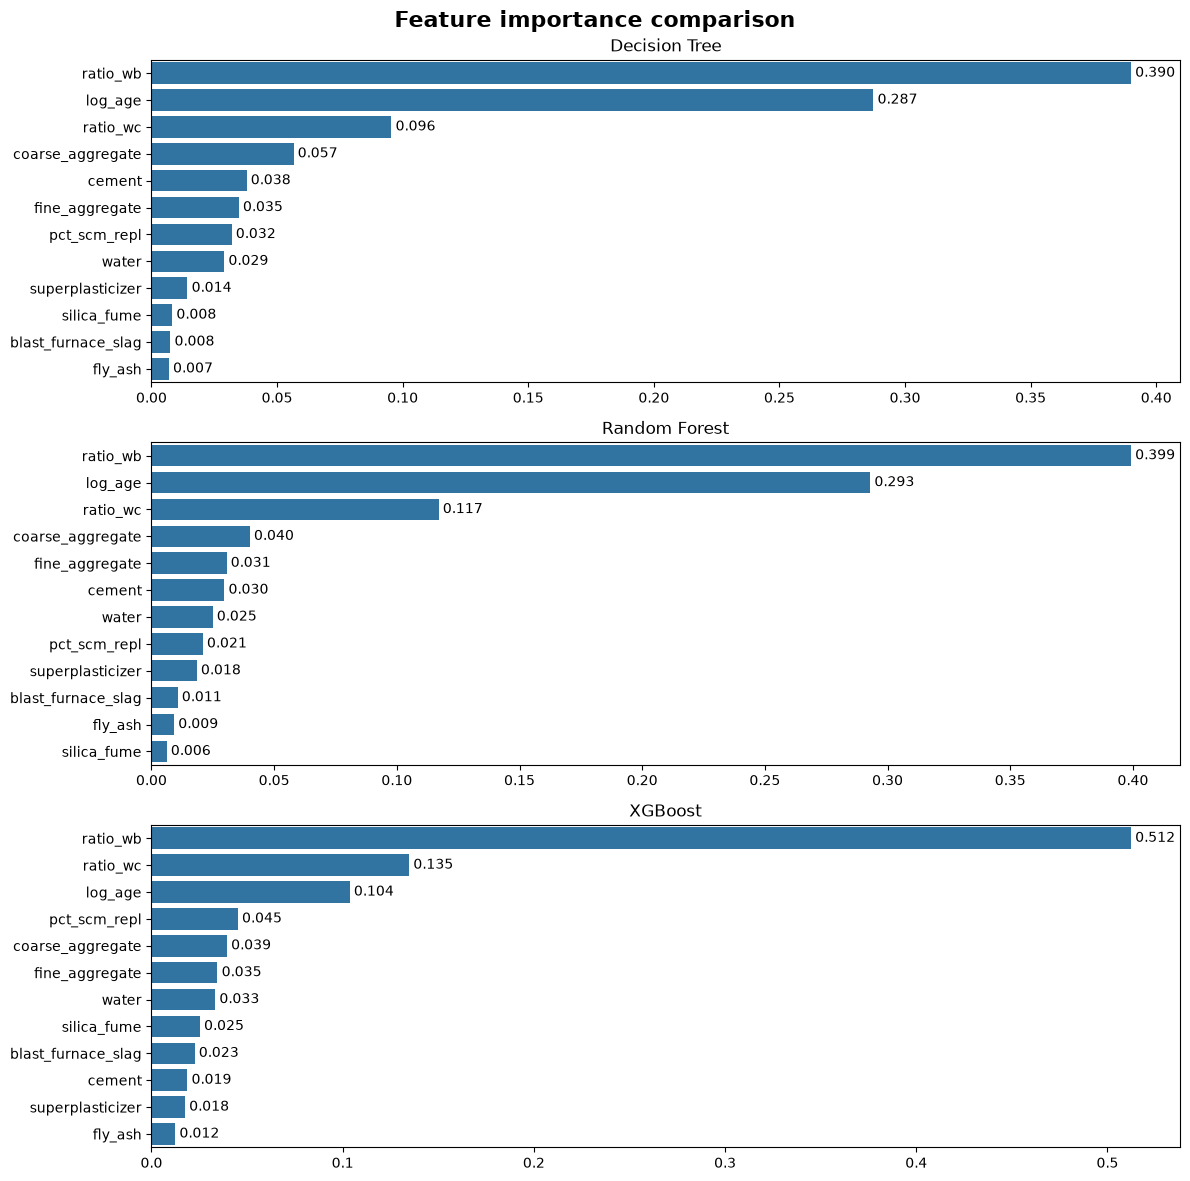

In [89]:
# Visualize feature importance
fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, ncols=1, figsize=(12, 12))

# Create bar plot for each model feature importance
sns.barplot(
    data=importances_dt.sort_values(key=abs, ascending=False),
    orient="h",
    ax=ax1
)
sns.barplot(
    data=importances_rf.sort_values(key=abs, ascending=False),
    orient="h",
    ax=ax2
)
sns.barplot(
    data=importances_xgb.sort_values(key=abs, ascending=False),
    orient="h",
    ax=ax3
)

# Add label to bars
for c in ax1.containers:
    ax1.bar_label(c, fmt="%.3f", padding=3)
for c in ax2.containers:
    ax2.bar_label(c, fmt="%.3f", padding=3)
for c in ax3.containers:
    ax3.bar_label(c, fmt="%.3f", padding=3)

ax1.set_title("Decision Tree")
ax2.set_title("Random Forest")
ax3.set_title("XGBoost")
fig.suptitle("Feature importance comparison", fontsize=16, fontweight="bold")

fig.tight_layout()

#### 3.7.2 - Permutation importance of tree-based models

- For permutation importance, use the validation set.
- For simplicity, we just consider MAE, RMSE, and R2.

In [90]:
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2_score": "r2"
}

# PI for decision tree
result_perm_importance_dt = permutation_importance(
    model_dtr, 
    X_val,
    y_val, 
    scoring=scoring,
    random_state=RANDOM_SEED
)

# PI for random forest
result_perm_importance_rf = permutation_importance(
    model_rfr, 
    X_val,
    y_val, 
    scoring=scoring,
    random_state=RANDOM_SEED
)

# PI for XGBoost
result_perm_importance_xgb = permutation_importance(
    model_xgbr, 
    X_val,
    y_val, 
    scoring=scoring,
    random_state=RANDOM_SEED
)

In [91]:
param = "mae"

df_perm_importances_dt = pd.DataFrame(
    {"importance": result_perm_importance_dt[param].importances_mean, "std": result_perm_importance_dt[param].importances_std}, 
    index=model_dtr.feature_names_in_
).sort_values(by="importance", ascending=False)

df_perm_importances_rf = pd.DataFrame(
    {"importance": result_perm_importance_rf[param].importances_mean, "std": result_perm_importance_rf[param].importances_std}, 
    index=model_rfr.feature_names_in_
).sort_values(by="importance", ascending=False)

df_perm_importances_xgb = pd.DataFrame(
    {"importance": result_perm_importance_xgb[param].importances_mean, "std": result_perm_importance_xgb[param].importances_std}, 
    index=model_xgbr.feature_names_in_
).sort_values(by="importance", ascending=False)

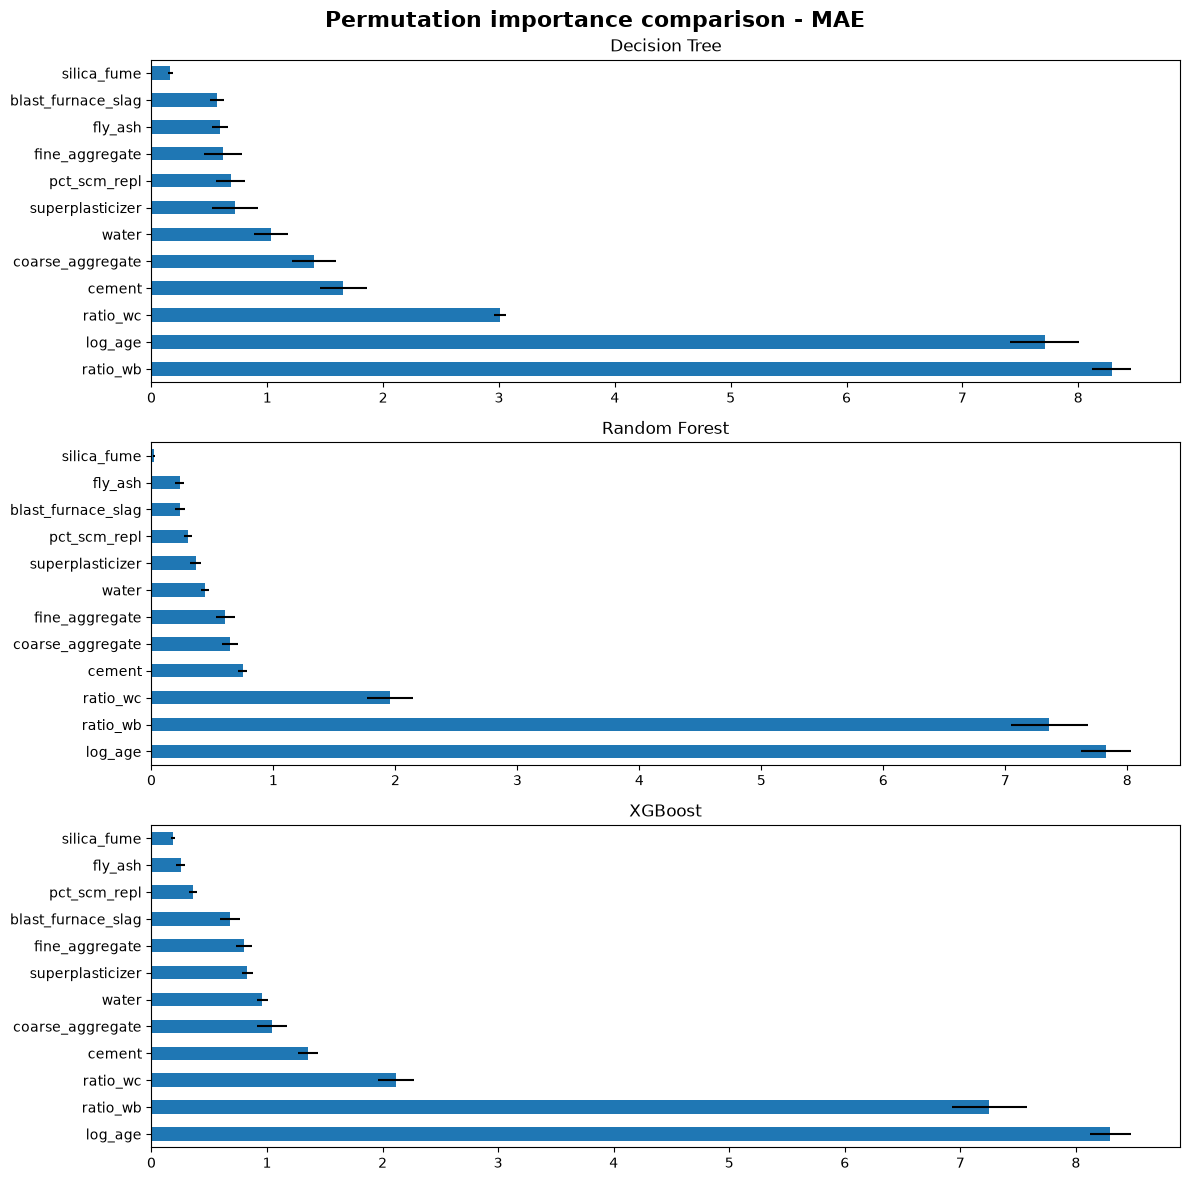

In [92]:
# Visualize permutation importance in MAE
fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, ncols=1, figsize=(12, 12))

df_perm_importances_dt["importance"].plot(
    kind="barh",
    xerr=df_perm_importances_dt["std"],
    ax=ax1
)
df_perm_importances_rf["importance"].plot(
    kind="barh",
    xerr=df_perm_importances_rf["std"],
    ax=ax2
)
df_perm_importances_xgb["importance"].plot(
    kind="barh",
    xerr=df_perm_importances_xgb["std"],
    ax=ax3
)

ax1.set_title("Decision Tree")
ax2.set_title("Random Forest")
ax3.set_title("XGBoost")
fig.suptitle("Permutation importance comparison - MAE", fontsize=16, fontweight="bold")

fig.tight_layout()

In [93]:
param = "rmse"

df_perm_importances_dt = pd.DataFrame(
    {"importance": result_perm_importance_dt[param].importances_mean, "std": result_perm_importance_dt[param].importances_std}, 
    index=model_dtr.feature_names_in_
).sort_values(by="importance", ascending=False)

df_perm_importances_rf = pd.DataFrame(
    {"importance": result_perm_importance_rf[param].importances_mean, "std": result_perm_importance_rf[param].importances_std}, 
    index=model_rfr.feature_names_in_
).sort_values(by="importance", ascending=False)

df_perm_importances_xgb = pd.DataFrame(
    {"importance": result_perm_importance_xgb[param].importances_mean, "std": result_perm_importance_xgb[param].importances_std}, 
    index=model_xgbr.feature_names_in_
).sort_values(by="importance", ascending=False)

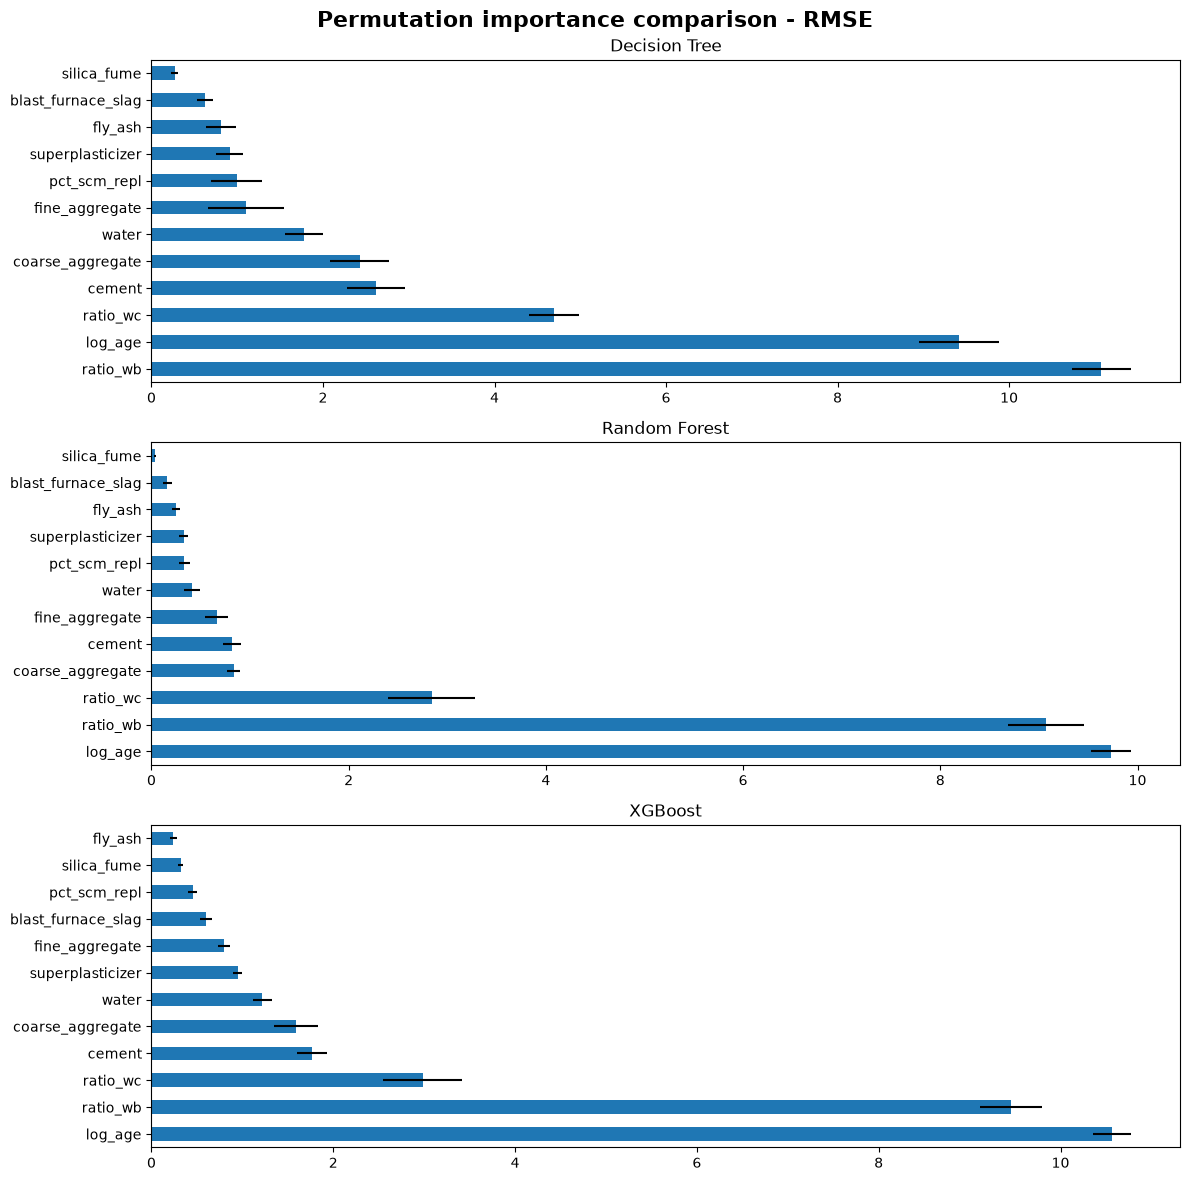

In [94]:
# Visualize permutation importance in RMSE
fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, ncols=1, figsize=(12, 12))

df_perm_importances_dt["importance"].plot(
    kind="barh",
    xerr=df_perm_importances_dt["std"],
    ax=ax1
)
df_perm_importances_rf["importance"].plot(
    kind="barh",
    xerr=df_perm_importances_rf["std"],
    ax=ax2
)
df_perm_importances_xgb["importance"].plot(
    kind="barh",
    xerr=df_perm_importances_xgb["std"],
    ax=ax3
)

ax1.set_title("Decision Tree")
ax2.set_title("Random Forest")
ax3.set_title("XGBoost")
fig.suptitle("Permutation importance comparison - RMSE", fontsize=16, fontweight="bold")

fig.tight_layout()

In [95]:
param = "r2_score"

df_perm_importances_dt = pd.DataFrame(
    {"importance": result_perm_importance_dt[param].importances_mean, "std": result_perm_importance_dt[param].importances_std}, 
    index=model_dtr.feature_names_in_
).sort_values(by="importance", ascending=False)

df_perm_importances_rf = pd.DataFrame(
    {"importance": result_perm_importance_rf[param].importances_mean, "std": result_perm_importance_rf[param].importances_std}, 
    index=model_rfr.feature_names_in_
).sort_values(by="importance", ascending=False)

df_perm_importances_xgb = pd.DataFrame(
    {"importance": result_perm_importance_xgb[param].importances_mean, "std": result_perm_importance_xgb[param].importances_std}, 
    index=model_xgbr.feature_names_in_
).sort_values(by="importance", ascending=False)

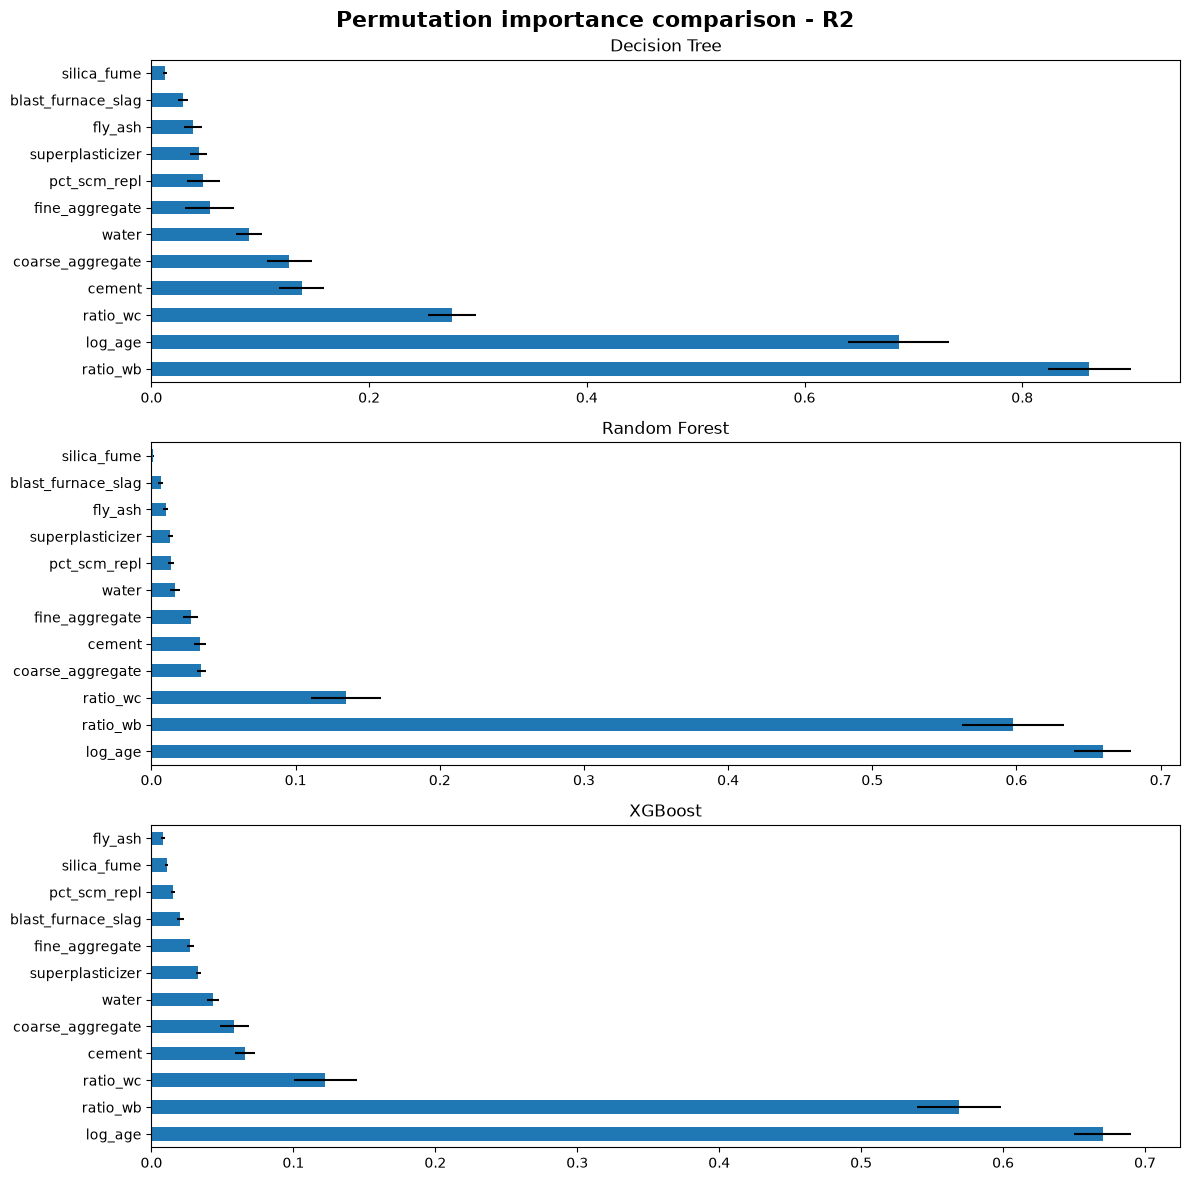

In [96]:
# Visualize permutation importance in R2
fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, ncols=1, figsize=(12, 12))

df_perm_importances_dt["importance"].plot(
    kind="barh",
    xerr=df_perm_importances_dt["std"],
    ax=ax1
)
df_perm_importances_rf["importance"].plot(
    kind="barh",
    xerr=df_perm_importances_rf["std"],
    ax=ax2
)
df_perm_importances_xgb["importance"].plot(
    kind="barh",
    xerr=df_perm_importances_xgb["std"],
    ax=ax3
)

ax1.set_title("Decision Tree")
ax2.set_title("Random Forest")
ax3.set_title("XGBoost")
fig.suptitle("Permutation importance comparison - R2", fontsize=16, fontweight="bold")

fig.tight_layout()

**Takeaway**

Looking at both feature and permutation importance, `log_age`, `ratio_wc`, and `ratio_wc` consistently make the most impact in the prediction.

#### 3.7.3 - SHAP importance of tree-based models

Background dataset has 326 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=326 when initializing the masker.


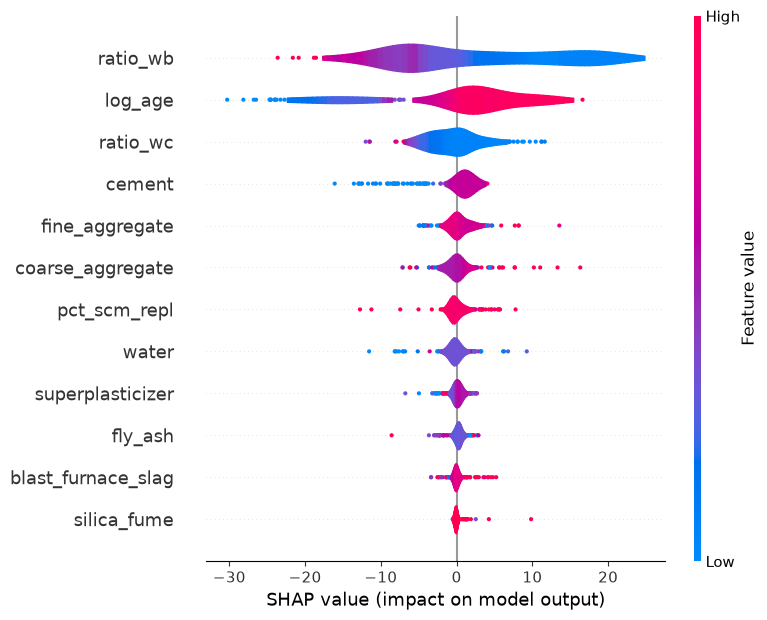

In [97]:
explainer = shap.Explainer(model_dtr, X_val)
shap_values = explainer(X_val)
shap.summary_plot(shap_values, plot_type="violin")

Background dataset has 326 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=326 when initializing the masker.


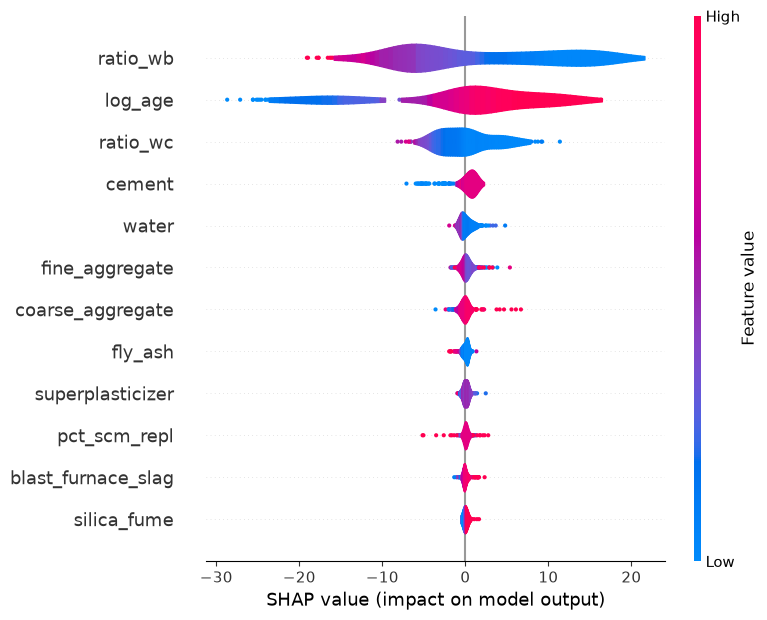

In [98]:
explainer = shap.Explainer(model_rfr, X_val)
shap_values = explainer(X_val)
shap.summary_plot(shap_values, plot_type="violin")

Background dataset has 326 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=326 when initializing the masker.


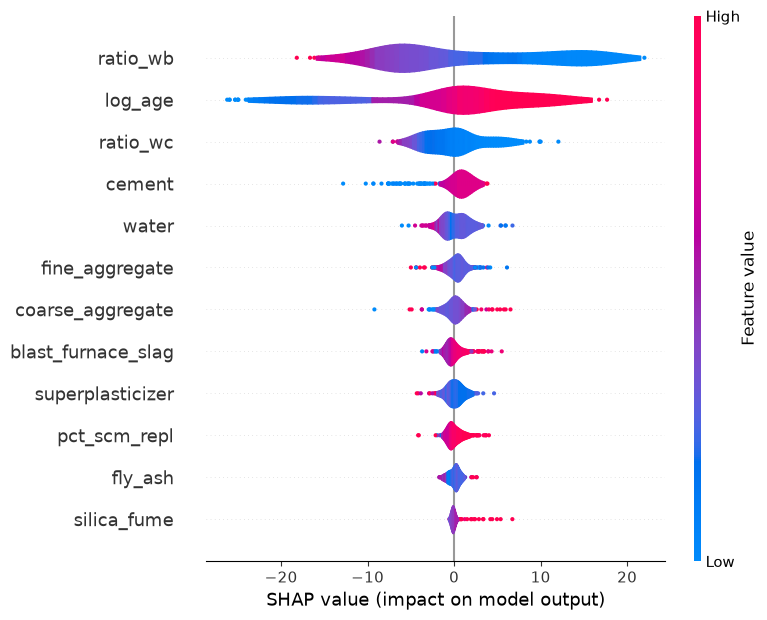

In [99]:
explainer = shap.Explainer(model_xgbr, X_val)
shap_values = explainer(X_val)
shap.summary_plot(shap_values, plot_type="violin")

To interpret SHAP values, consider the `ratio_wb` feature.

- As the value goes lower, the SHAP value gets higher. This means lower ratio results to a large increase in the prediction (which in our case, the concrete strength).
- In general, the summary plots not only order features by their effect on prediction but also how higher and lower values of the feature will affect the result.

#### 3.7.4 - Permutation importance for SVM

In [100]:
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2_score": "r2"
}

# PI for SVR
result_perm_importance_svr = permutation_importance(
    model_svr, 
    X_val,
    y_val, 
    scoring=scoring,
    random_state=RANDOM_SEED
)

In [101]:
df_perm_importances_svr_mae = pd.DataFrame(
    {"importance": result_perm_importance_svr["mae"].importances_mean, "std": result_perm_importance_svr["mae"].importances_std}, 
    index=model_svr.feature_names_in_
).sort_values(by="importance", ascending=False)

df_perm_importances_svr_rmse = pd.DataFrame(
    {"importance": result_perm_importance_svr["rmse"].importances_mean, "std": result_perm_importance_svr["rmse"].importances_std}, 
    index=model_svr.feature_names_in_
).sort_values(by="importance", ascending=False)

df_perm_importances_svr_r2 = pd.DataFrame(
    {"importance": result_perm_importance_svr["r2_score"].importances_mean, "std": result_perm_importance_svr["r2_score"].importances_std}, 
    index=model_svr.feature_names_in_
).sort_values(by="importance", ascending=False)

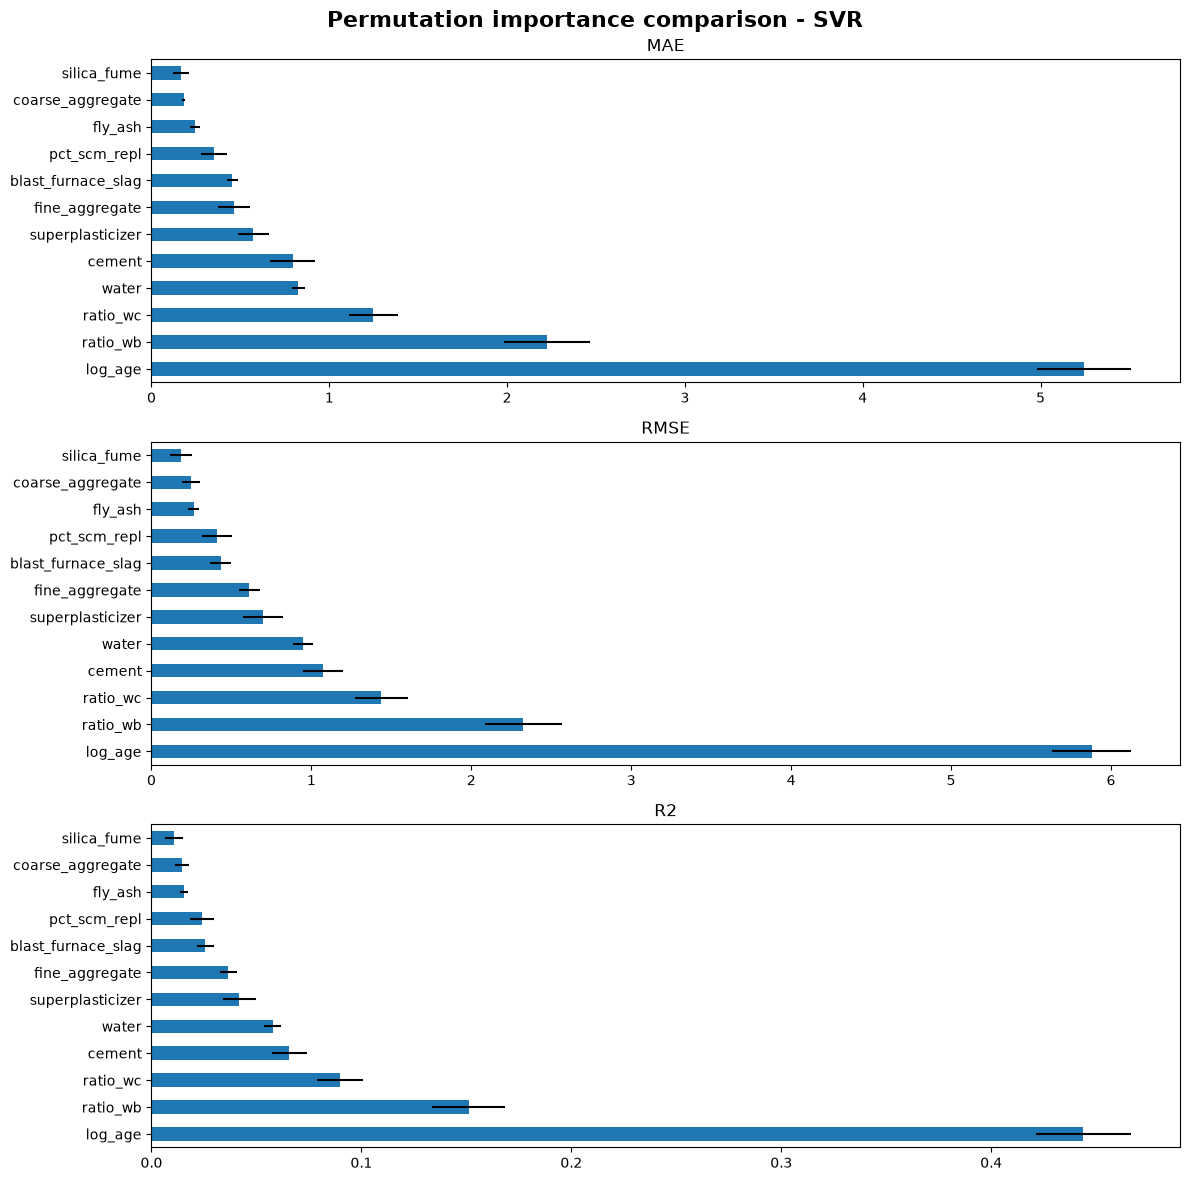

In [102]:
fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, ncols=1, figsize=(12, 12))

df_perm_importances_svr_mae["importance"].plot(
    kind="barh",
    xerr=df_perm_importances_svr_mae["std"],
    ax=ax1
)
df_perm_importances_svr_rmse["importance"].plot(
    kind="barh",
    xerr=df_perm_importances_svr_rmse["std"],
    ax=ax2
)
df_perm_importances_svr_r2["importance"].plot(
    kind="barh",
    xerr=df_perm_importances_svr_r2["std"],
    ax=ax3
)

ax1.set_title("MAE")
ax2.set_title("RMSE")
ax3.set_title("R2")
fig.suptitle("Permutation importance comparison - SVR", fontsize=16, fontweight="bold")

fig.tight_layout()

The result also shows that `log_age`, `ratio_wc`, and `ratio_wb` make the most impact in the prediction should we use SVM as a model for making predictions to strength.

## 4 - Takeaways

- For finetuning and cross-validation, its important to transform `age` into `log_age`.
- Between `ratio_wb` (water-binder ratio) and `ratio_wc` (water-cement ratio), it's more logical to retain `ratio_wb` and disregard `ratio_wc` since it reduces to the latter when there's no SCM added in a sample mix, or in other words, cement is only the binder present. The feature importance results further support this as `ratio_wb` has more impact to prediction than `ratio_wc`. 
- Because `pct_scm_repl` doesn't make a significant impact to prediction, it could be optionally disregarded in the process. But we'll keep it for the purpose of interpretability of the model.
- Reduce the choice of model to Random Forest, XGBoost, and SVM. Then pick the final model that will yield the best score after finetuning and cross-validation.